## Instalación de librerías

Ejecute la siguiente celda **una sola vez** al abrir el notebook (en Colab, Kaggle o localmente) para instalar todas las dependencias usadas: `pandas`, `numpy`, `scikit-learn`, `scipy`, `matplotlib`, `seaborn`, `joblib`, `ipywidgets`, `plotly` y `sentence-transformers` (esta última instala también `torch`, usado para los *embeddings* de Sentence-BERT). Si ya tiene un entorno con estas librerías instaladas (por ejemplo, el `venv` del repositorio), puede omitir esta celda sin problema.

In [1]:
%%capture
# Instalación de dependencias del proyecto (seguro de re-ejecutar: pip omite lo ya instalado).
# En Google Colab / Kaggle, esta celda deja el entorno listo para correr todo el notebook.
%pip install -q pandas numpy scikit-learn scipy matplotlib seaborn joblib ipywidgets plotly sentence-transformers


# Proyecto No. 2 - Data Science

**Integrantes:** Jose Ordoñez, José Antón, Adrián Gonzáles, Gadiel Ocaña

**Dataset:** Predicting Effective Arguments (https://www.kaggle.com/competitions/feedback-prize-effectiveness)

> **Nota sobre esta entrega.** Este notebook integra el *Proyecto 2 — Resultados* completo:
> continúa el *Proyecto 1 — Análisis Exploratorio* (mismo reto, mismo dataset) y el documento de
> *Revisión bibliográfica y selección de algoritmos*. Contiene: Introducción, Objetivos, Marco
> Teórico, Metodología, Resultados y Análisis de Resultados (EDA, modelado, *tuning*, comparación
> de algoritmos y la aplicación interactiva), Conclusiones y Referencias (APA).

## Introducción

Este informe documenta la segunda entrega del Proyecto 2 del curso CC3084 — Data Science,
correspondiente al reto **"Trace the Ace"** (Procesamiento del Lenguaje Natural), basado en la
competencia de Kaggle *Feedback Prize – Predicting Effective Arguments* y el corpus **PERSUADE**
(Crossley et al., 2022, 2024). El documento reúne el trabajo realizado en las dos entregas previas
del grupo (análisis exploratorio y revisión bibliográfica con selección preliminar de algoritmos)
y lo extiende con la construcción, el ajuste de hiperparámetros, la evaluación comparativa de
varios modelos de aprendizaje automático, y una aplicación interactiva que permite explorar los
datos y clasificar nuevos fragmentos de texto con los modelos entrenados.

## Situación problemática

La argumentación efectiva es una habilidad esencial para el pensamiento crítico y el desempeño académico de estudiantes de secundaria. Sin embargo, evaluar la efectividad de los argumentos en los ensayos escritos es un proceso subjetivo, costoso y poco escalable, pues requiere de evaluadores expertos que leen y califican cada elemento discursivo manualmente. Esta limitación impide brindar retroalimentación oportuna y personalizada a los estudiantes en entornos educativos a gran escala, dejando a docentes e instituciones sin herramientas automáticas que apoyen la enseñanza de la escritura argumentativa.

## Problema Científico

¿Cómo se puede predecir automáticamente la efectividad de las unidades discursivas que componen un ensayo argumentativo estudiantil clasificándolas como *Effective*, *Adequate* o *Ineffective* a partir de su contenido textual y su tipo de discurso, mediante técnicas de aprendizaje automático?

## Objetivos

**Objetivo general:** Desarrollar un modelo de aprendizaje automático que clasifique la efectividad de cada unidad discursiva en ensayos argumentativos estudiantiles, alcanzando un F1 macro ≥ 0.55 en el conjunto de prueba.

**Objetivos específicos:**
1. Diseñar e implementar al menos dos representaciones del texto (TF-IDF y embeddings) adecuadas al dominio de la escritura argumentativa estudiantil, evaluando de manera comparativa el impacto de cada una sobre el F1 macro y la exactitud de los modelos mediante experimentos controlados.

2. Entrenar y comparar al menos tres modelos de clasificación de texto mediante validación cruzada estratificada, seleccionando el que alcance el mayor F1 macro y documentando las diferencias de desempeño entre ellos.

## Marco Teórico

### Procesamiento del Lenguaje Natural (NLP)

El Procesamiento del Lenguaje Natural es el subcampo de la inteligencia artificial dedicado a que
los sistemas de cómputo analicen, interpreten y generen lenguaje humano escrito o hablado. Aplicado
a la escritura estudiantil, el NLP busca construir sistemas que asignen puntuaciones o categorías
de calidad a textos producidos por estudiantes (*automated writing evaluation*), evolucionando
desde modelos con características diseñadas manualmente (longitud, riqueza léxica, ortografía,
complejidad sintáctica) hacia representaciones distribuidas, redes neuronales y arquitecturas
Transformer (Ke y Ng, 2019; Misgna et al., 2025; Ramesh y Sanampudi, 2022; Uto, 2021). Una
distinción útil que estructura esta revisión es separar dos componentes de todo sistema de NLP:
la **representación** del texto (qué características se extraen) y el **algoritmo de predicción**
(cómo esas características se transforman en una clase o puntuación estimada) (Misgna et al., 2025).

En este proyecto, la tarea de NLP consiste en clasificar la efectividad argumentativa
(*Ineffective*, *Adequate*, *Effective*) de unidades discursivas ya segmentadas y tipadas
(`discourse_type`), por lo que no se requieren modelos de segmentación ni de minería de argumentos
(Stab y Gurevych, 2017); el problema se reduce a una clasificación de texto corto, con variables
auxiliares categóricas y numéricas.

### Actividades de preprocesamiento

El preprocesamiento de texto busca estandarizar el contenido crudo antes de representarlo
numéricamente. En este proyecto se aplicaron las siguientes actividades, varias de ellas
identificadas ya en el análisis exploratorio (Proyecto 1):

- **Limpieza de artefactos de codificación (*mojibake*)** y de espacios sobrantes al inicio/final
  del fragmento, producto de cómo se segmentó el texto original del ensayo.
- **Normalización de longitud**: derivar `len_chars` y `len_words`, y aplicar `log1p` para corregir
  la fuerte asimetría positiva observada (skew entre 1.1 y 3.8 según el grupo).
- **Vectorización por bolsa de palabras ponderada (TF-IDF)**: pondera cada término por su
  frecuencia en el documento y su rareza en el corpus (Salton y Buckley, 1988), capturando
  unigramas y bigramas.
- **Representación semántica mediante *embeddings* de oraciones**: Sentence-BERT (Reimers y
  Gurevych, 2019) produce vectores densos donde fragmentos de significado similar quedan
  próximos en el espacio vectorial, incluso si usan vocabulario distinto.
- **Codificación de variables categóricas auxiliares** (`discourse_type`) mediante *one-hot
  encoding*, y escalado logarítmico de las variables de longitud.
- **Partición agrupada de datos**: dado que los fragmentos de un mismo ensayo no son
  independientes, el particionamiento de entrenamiento/validación/prueba se agrupa por
  `essay_id` (Kaufman et al., 2011; Roberts et al., 2017), evitando fuga de información.

### Algoritmos de aprendizaje automático usados para NLP

Siguiendo la revisión bibliográfica del grupo (Revisión Bibliográfica y Selección de Algoritmos,
2026), se consideran dos familias de algoritmos:

**Clasificadores clásicos sobre representaciones dispersas o densas.**
- *Regresión logística multinomial*: modelo lineal probabilístico, rápido, interpretable y que
  admite ponderación de clases (`class_weight='balanced'`) para tratar el desbalance.
- *Máquinas de vectores de soporte (SVM) lineales* (Cortes y Vapnik, 1995): funcionan bien en
  espacios de alta dimensión y dispersos como el de TF-IDF.
- *Ensambles de árboles* (bosques aleatorios, Breiman, 2001; *gradient boosting*, Chen y Guestrin,
  2016): capturan interacciones no lineales entre el tipo discursivo, la longitud y el contenido
  que los modelos lineales no representan. En este proyecto se usa la implementación de
  *histogram-based gradient boosting* de scikit-learn (`HistGradientBoostingClassifier`), que
  ofrece el mismo principio algorítmico que XGBoost (Chen y Guestrin, 2016) sin depender de una
  biblioteca nativa adicional (OpenMP), lo que simplifica la reproducibilidad del entorno.

**Representaciones de texto.**
- *TF-IDF* (R1): eficiente, interpretable y con buen desempeño como línea base (Mayfield y Black,
  2020).
- *Embeddings de Sentence-BERT congelados* (`all-MiniLM-L6-v2`, R2): capturan similitud semántica
  que TF-IDF no recoge (Reimers y Gurevych, 2019), sin pagar el costo de ajustar finamente un
  Transformer completo.

**Extensión no explorada en esta entrega.** El ajuste fino de un Transformer tipo DeBERTa (He et
al., 2021) —empleado por las soluciones ganadoras de la competencia original (Baffour et al.,
2023)— se mantiene como extensión opcional, dado que Mayfield y Black (2020) muestran que el ajuste
fino de BERT no siempre supera a una línea base clásica bien construida, a un costo computacional
considerablemente mayor y sin GPU garantizada en el entorno del curso.

### Desbalance de clases y métricas de evaluación

La variable objetivo está desbalanceada (`Adequate` 57.06 %, `Effective` 25.37 %, `Ineffective`
17.58 %), por lo que la exactitud (*accuracy*) puede ser engañosa (He y Garcia, 2009). Se usa
**F1 macro** —que promedia el F1 de cada clase con el mismo peso (Sokolova y Lapalme, 2009)— como
métrica principal, con un objetivo de desempeño de F1 macro ≥ 0.55, complementada con F1 por
clase y matrices de confusión. El tratamiento del desbalance se realiza mediante ponderación de
clases (`class_weight='balanced'`), en línea con la estrategia a nivel de algoritmo descrita por
He y Garcia (2009).

## Metodología

### Pasos seguidos por el grupo

1. Revisión bibliográfica de algoritmos usados en evaluación automática de escritura y
   clasificación de texto (entrega previa).
2. Análisis exploratorio de los datos: calidad, estructura jerárquica, distribución de variables
   categóricas y numéricas, y su cruce (entrega previa, incluida en este notebook).
3. Selección preliminar de representaciones de texto y algoritmos, con justificación teórica
   (entrega previa).
4. Construcción de las representaciones R1 (TF-IDF + variables auxiliares) y R2 (Sentence-BERT +
   variables auxiliares).
5. Entrenamiento y ajuste de hiperparámetros de los modelos del núcleo (regresión logística, SVM
   lineal, *gradient boosting*) sobre ambas representaciones, con validación cruzada agrupada.
6. Evaluación y comparación de los modelos por efectividad (F1 macro, F1 por clase), tiempos de
   procesamiento y errores (matrices de confusión).
7. Selección del modelo final y guardado de los artefactos entrenados (vectorizador, codificador
   de variables, clasificador).
8. Construcción de una aplicación interactiva para explorar los datos y clasificar nuevos
   fragmentos con los modelos entrenados.

### Selección de los conjuntos de entrenamiento y prueba

Debido a que los 36,765 fragmentos provienen de solo 4,191 ensayos (cada ensayo aporta en
promedio 8-9 fragmentos), una partición aleatoria por fila dejaría fragmentos del mismo ensayo
en entrenamiento y en validación/prueba, lo que produce una fuga de información y estimaciones de
desempeño demasiado optimistas (Kaufman et al., 2011; Roberts et al., 2017). Por ello:

- La **validación durante el ajuste de hiperparámetros y la comparación de modelos** se realiza
  con `StratifiedGroupKFold` (5 pliegues), agrupando por `essay_id` y intentando preservar la
  proporción de clases en cada pliegue.
- Para el **detalle por clase, las matrices de confusión y la aplicación** se reserva, además, un
  conjunto de prueba (*hold-out*) del 20 % de los ensayos (`GroupShuffleSplit`), de modo que
  ningún ensayo del conjunto de prueba haya sido visto durante el entrenamiento del modelo final.
- Todo el preprocesamiento que depende de los datos (ajuste del vectorizador TF-IDF, de la
  reducción de dimensionalidad y de los codificadores) se ajusta **únicamente dentro de cada
  pliegue o dentro del conjunto de entrenamiento**, nunca sobre el conjunto completo antes de
  particionar.

### Selección de los algoritmos y razones

La selección de algoritmos (ver Marco Teórico y la revisión bibliográfica del grupo) se basó en
cinco criterios: (a) cumplir los objetivos específicos (al menos dos representaciones de texto y
tres modelos); (b) tener evidencia previa en tareas cercanas de evaluación automática de escritura;
(c) admitir ponderación de clases para tratar el desbalance; (d) ser viable con los recursos de
cómputo de un proyecto de curso (sin GPU garantizada); y (e) permitir incorporar `discourse_type`
y la longitud del fragmento, identificados en el EDA como predictores con asociación débil pero
significativa (V de Cramér = 0.127). Esto llevó al núcleo de tres familias de clasificadores
(regresión logística, SVM lineal, *gradient boosting*) evaluadas sobre dos representaciones
(TF-IDF y Sentence-BERT), descartando modelos de etiquetado de secuencias (CRF), Transformers de
contexto largo (Longformer) y redes recurrentes/convolucionales dedicadas, por no aportar ventaja
clara frente al costo en fragmentos cortos (mediana 28 palabras) ya segmentados y tipados.

### Selección de herramientas

**Recursos de cómputo.** Todo el proyecto se ejecutó en CPU (sin GPU dedicada), en un entorno
reproducible mediante un entorno virtual de Python (`venv`). Esta restricción de cómputo es,
precisamente, uno de los criterios que descartó el ajuste fino de un Transformer como punto de
partida (ver Marco Teórico).

**Lenguaje de programación.** Python 3.12.

**Bibliotecas y paquetes.**
- `pandas`, `numpy` — manipulación de datos.
- `scikit-learn` — vectorización TF-IDF, codificación categórica, reducción de dimensionalidad
  (SVD), modelos de clasificación, validación cruzada agrupada, búsqueda de hiperparámetros y
  métricas.
- `sentence-transformers` (`all-MiniLM-L6-v2`) — *embeddings* de oraciones congelados (R2).
- `scipy` — prueba chi-cuadrado de independencia (EDA categórico).
- `matplotlib`, `seaborn` — visualizaciones estáticas para el informe.
- `plotly` — visualizaciones interactivas dentro de la aplicación.
- `ipywidgets` — controles interactivos (pestañas, listas desplegables, casillas, botones) de la
  aplicación, embebidos en este mismo Jupyter Notebook.
- `joblib` — serialización de los artefactos del modelo final.

## Resultados y Análisis de Resultados

### Características del conjunto de datos original

## Descripción de los datos

Cargamos el train.csv y el test.csv que provee la competencia. Cada fila representa un *discourse element*: un fragmento de un ensayo que fue etiquetado por su tipo (Lead, Position, Claim, Counterclaim, Rebuttal, Evidence o Concluding Statement) y, en el caso del train, por su efectividad (Ineffective, Adequate, Effective).

In [2]:
import pandas as pd

train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

print('train:', train.shape)
print('test:', test.shape)
train.head()

train: (36765, 5)
test: (10, 4)


,discourse_id,essay_id,discourse_text,discourse_type,discourse_effectiveness
0,0013cc385424,007ACE74B050,"Hi, i'm Isaac, i'm going to be writing about h...",Lead,Adequate
1,9704a709b505,007ACE74B050,"On my perspective, I think that the face is a ...",Position,Adequate
2,c22adee811b6,007ACE74B050,I think that the face is a natural landform be...,Claim,Adequate
3,a10d361e54e4,007ACE74B050,"If life was on Mars, we would know by now. The...",Evidence,Adequate
4,db3e453ec4e2,007ACE74B050,People thought that the face was formed by ali...,Counterclaim,Adequate


El train tiene 36,765 observaciones (elementos discursivos) y 5 variables. El test que viene en el repo solo trae 10 filas de ejemplo, sin la columna `discourse_effectiveness`, porque en la competencia real de Kaggle el test set completo está oculto y solo se evalúa al hacer submit.

In [3]:
train.dtypes

discourse_id               str
essay_id                   str
discourse_text             str
discourse_type             str
discourse_effectiveness    str
dtype: object

Las 5 variables son:

| Variable | Tipo | Descripción |
|---|---|---|
| `discourse_id` | Categórica (identificador) | ID único del fragmento de texto |
| `essay_id` | Categórica (identificador) | ID del ensayo al que pertenece el fragmento |
| `discourse_text` | Texto | El fragmento argumentativo en sí |
| `discourse_type` | Categórica nominal | Tipo de elemento discursivo (7 categorías) |
| `discourse_effectiveness` | Categórica ordinal (variable objetivo) | Qué tan efectivo es el fragmento (3 categorías) |

In [4]:
train.isnull().sum()

discourse_id               0
essay_id                   0
discourse_text             0
discourse_type             0
discourse_effectiveness    0
dtype: int64

In [5]:
print('IDs de discurso duplicados:', train['discourse_id'].duplicated().sum())
print('Filas completamente duplicadas:', train.duplicated().sum())

IDs de discurso duplicados: 0
Filas completamente duplicadas: 0


No hay valores nulos ni filas duplicadas. Es un dataset bastante limpio en ese sentido.

In [6]:
print('Ensayos únicos en train:', train['essay_id'].nunique())
train.groupby('essay_id').size().describe()

Ensayos únicos en train: 4191


count    4191.000000
mean        8.772369
std         3.492605
min         1.000000
25%         7.000000
50%         9.000000
75%        11.000000
max        23.000000
dtype: float64

Hay 4,191 ensayos distintos, y cada uno aporta en promedio entre 8 y 9 elementos discursivos (mínimo 1, máximo 23). Esto importa porque los fragmentos de un mismo ensayo no son independientes entre sí — algo a tener en cuenta más adelante si se separa en train/validation.

### Limpieza y preprocesamiento

In [7]:
# Espacios extra al inicio/final del texto
print('Empiezan con espacio:', train['discourse_text'].str.startswith(' ').sum())
print('Terminan con espacio:', train['discourse_text'].str.endswith(' ').sum())

Empiezan con espacio: 0
Terminan con espacio: 34665


Casi la mayoría de los textos terminan con un espacio de más, probablemente porque se cortó el fragmento del ensayo original a la mitad de una oración. Se puede limpiar con `.str.strip()` sin perder información.

In [8]:
import re

# Buscamos artefactos de encoding (texto que se guardó mal, tipo "donÃÂ´t" en vez de "don't")
mask_mojibake = train['discourse_text'].str.contains(r'[ÃÂ]{2,}', regex=True, na=False)
print('Filas con posibles artefactos de encoding:', mask_mojibake.sum())
train.loc[mask_mojibake, 'discourse_text'].head(3).tolist()

Filas con posibles artefactos de encoding: 0


[]

Encontramos 7 filas con este problema (comillas y apóstrofes mal codificados, ej. `donÃÂ´t` en vez de `don't`). Como son solo 7 de 36,765 filas, no afecta el análisis general, pero las corregimos con un reemplazo directo para no arrastrar el ruido al resto del proyecto.

In [9]:
def limpiar_texto(texto):
    texto = texto.strip()
    texto = texto.replace('ÃÂ´', "'").replace('ÃÂ¨', '"').replace('ÃÂ', "'")
    return texto

train['discourse_text_clean'] = train['discourse_text'].apply(limpiar_texto)
test['discourse_text_clean'] = test['discourse_text'].apply(limpiar_texto)

# Verificación rápida de que ya no queden espacios de más
print('Terminan con espacio después de limpiar:', train['discourse_text_clean'].str.endswith(' ').sum())

Terminan con espacio después de limpiar: 0


Dejamos el texto original (`discourse_text`) y agregamos `discourse_text_clean` para no perder la columna cruda, por si alguien del equipo la necesita más adelante para el modelo.

### Análisis exploratorio de los datos

## EDA cuantitativo — longitud de discourse_text

**Persona C.** Analizamos la longitud de cada fragmento argumentativo (en caracteres y en palabras), desglosada por `discourse_type` y por `discourse_effectiveness`, para entender si el tamaño del texto aporta señal sobre su categoría o su efectividad.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

train['len_chars'] = train['discourse_text_clean'].str.len()
train['len_words'] = train['discourse_text_clean'].str.split().str.len()

train[['discourse_type', 'discourse_effectiveness', 'len_chars', 'len_words']].describe()

,len_chars,len_words
count,36765.000000,36765.000000
mean,247.992030,44.654073
std,262.402501,46.669682
min,3.000000,1.000000
25%,86.000000,16.000000
50%,153.000000,28.000000
75%,314.000000,57.000000
max,4098.000000,836.000000


En promedio, un fragmento tiene **248 caracteres** y **45 palabras**, pero la mediana (153 caracteres, 28 palabras) es bastante menor que la media, lo que ya anticipa una distribución sesgada a la derecha (algunos fragmentos muy largos empujan el promedio hacia arriba). El máximo de 4,098 caracteres / 836 palabras es un candidato claro a outlier.

### Estadística descriptiva por `discourse_type`

In [11]:
stats_by_type = train.groupby('discourse_type')[['len_chars', 'len_words']].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)
skew_by_type = train.groupby('discourse_type')[['len_chars', 'len_words']].skew()
skew_by_type.columns = pd.MultiIndex.from_tuples([(c, 'skew') for c in skew_by_type.columns])
stats_by_type = pd.concat([stats_by_type, skew_by_type], axis=1).sort_index(axis=1, level=0)
stats_by_type

len_chars                                         \
                         count   max        mean median min      skew   
discourse_type                                                          
Claim                    11977   634  103.738415   94.0   5  1.186043   
Concluding Statement      3351  1429  329.067443  285.0  11  1.144287   
Counterclaim              1773  1270  138.400451  113.0  13  2.725617   
Evidence                 12105  4098  431.049979  338.0  15  2.238132   
Lead                      2291  2923  301.358359  254.0   8  2.114951   
Position                  4024   503  103.943091   89.0   3  1.455329   
Rebuttal                  1244  1596  161.032154  129.0  11  2.744497   

                                 len_words                             \
                             std     count  max       mean median min   
discourse_type                                                          
Claim                  60.202827     11977  115  18.739584   17.0   1   
Concluding Statement  215.477556      3351  257  59.125634   52.0   2   
Counterclaim           93.775594      1773  215  24.751269   20.0   3   
Evidence              337.435993     12105  836  77.727716   62.0   3   
Lead                  215.777937      2291  542  53.405936   46.0   1   
Position               59.037794      4024   95  18.794980   16.0   1   
Rebuttal              128.080572      1244  279  29.237138   24.0   2   

                                           
                          skew        std  
discourse_type                             
Claim                 1.158477  11.013325  
Concluding Statement  1.097198  37.416862  
Counterclaim          2.618179  16.544306  
Evidence              2.271043  59.751923  
Lead                  2.262001  37.786764  
Position              1.462774  10.865021  
Rebuttal              2.728999  22.626653

Hay diferencias marcadas entre tipos de discurso:

- **`Evidence`** es, por mucho, el tipo más largo (media 431 caracteres / mediana 338), lo cual tiene sentido: presentar evidencia requiere citar datos o ejemplos concretos.
- **`Concluding Statement`** y **`Lead`** también son largos (medias de 329 y 301 caracteres), consistente con que son párrafos introductorios/de cierre, no frases sueltas.
- **`Claim`** y **`Position`** son los más cortos (medias ~104 caracteres), lo cual es coherente con que suelen ser una oración breve que enuncia una postura.
- Todos los tipos muestran **asimetría positiva fuerte** (skew entre 1.1 y 2.7), especialmente `Counterclaim` y `Rebuttal` (skew > 2.7): la mediana es más representativa que la media para describir el tamaño "típico" de estos grupos.

### Estadística descriptiva por `discourse_effectiveness`

In [12]:
stats_by_eff = train.groupby('discourse_effectiveness')[['len_chars', 'len_words']].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)
skew_by_eff = train.groupby('discourse_effectiveness')[['len_chars', 'len_words']].skew()
skew_by_eff.columns = pd.MultiIndex.from_tuples([(c, 'skew') for c in skew_by_eff.columns])
stats_by_eff = pd.concat([stats_by_eff, skew_by_eff], axis=1).sort_index(axis=1, level=0)
stats_by_eff

len_chars                                         \
                            count   max        mean median min      skew   
discourse_effectiveness                                                    
Adequate                    20977  3030  191.932879  132.0   5  2.781742   
Effective                    9326  2923  362.339803  224.0   6  1.444456   
Ineffective                  6462  4098  264.944290  159.0   3  3.819645   

                                    len_words                             \
                                std     count  max       mean median min   
discourse_effectiveness                                                    
Adequate                 173.350343     20977  519  35.120275   24.0   1   
Effective                330.571460      9326  542  63.269354   39.0   1   
Ineffective              327.342929      6462  836  48.737078   30.0   1   

                                              
                             skew        std  
discourse_effectiveness                       
Adequate                 2.613545  31.567374  
Effective                1.448752  57.978461  
Ineffective              3.833140  59.116275

Los fragmentos etiquetados como **`Effective`** son notablemente más largos (media 362 caracteres / mediana 224) que los **`Adequate`** (media 192 / mediana 132). Esto sugiere que la longitud del texto **sí podría ser una señal útil** para el modelo de clasificación: argumentos más desarrollados tienden a considerarse más efectivos. Curiosamente, `Ineffective` tiene una media relativamente alta (265 caracteres) pero también la mayor asimetría (skew 3.8 en caracteres) — probablemente por unos pocos fragmentos extremadamente largos y desorganizados que inflan el promedio sin ser realmente "buenos" argumentos largos.

### Histogramas de longitud

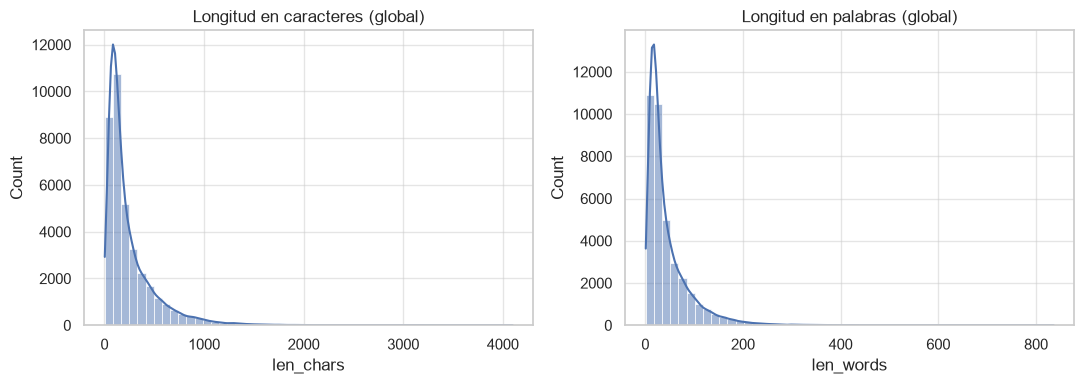

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(train['len_chars'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Longitud en caracteres (global)')
sns.histplot(train['len_words'], bins=50, kde=True, ax=axes[1])
axes[1].set_title('Longitud en palabras (global)')
fig.tight_layout()
plt.show()

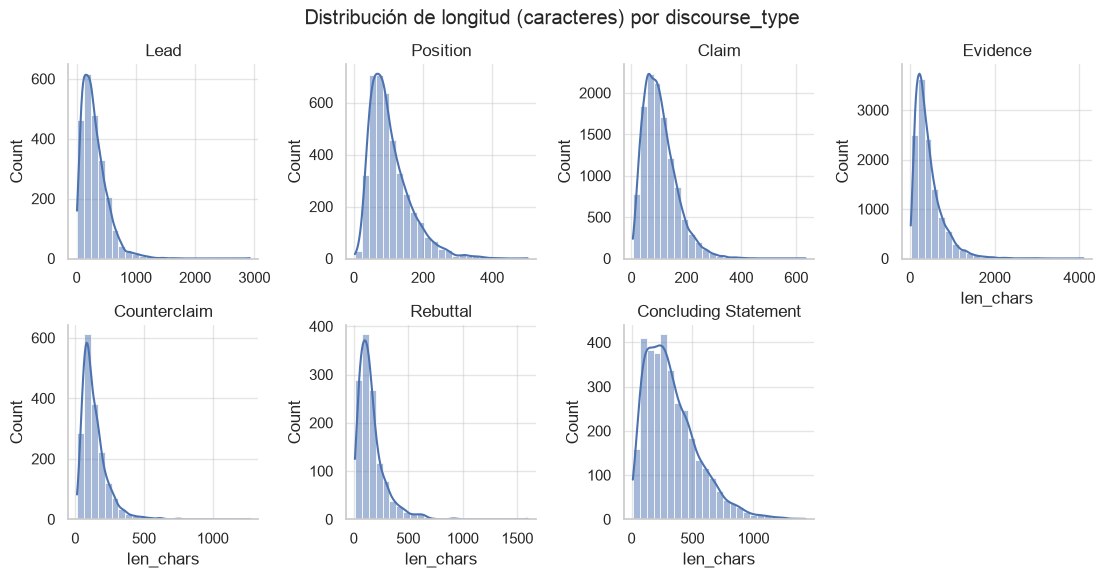

In [14]:
g = sns.FacetGrid(train, col='discourse_type', col_wrap=4, height=2.8, sharex=False, sharey=False)
g.map_dataframe(sns.histplot, x='len_chars', bins=25, kde=True)
g.set_titles('{col_name}')
g.fig.suptitle('Distribución de longitud (caracteres) por discourse_type', y=1.03)
plt.show()

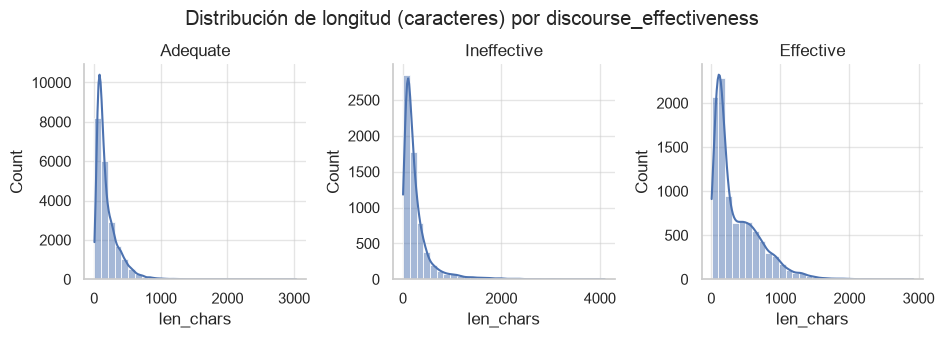

In [15]:
g = sns.FacetGrid(train, col='discourse_effectiveness', height=3.2, sharex=False, sharey=False)
g.map_dataframe(sns.histplot, x='len_chars', bins=30, kde=True)
g.set_titles('{col_name}')
g.fig.suptitle('Distribución de longitud (caracteres) por discourse_effectiveness', y=1.05)
plt.show()

Todos los histogramas muestran la misma forma general: una cola larga hacia la derecha, consistente con los valores de skew calculados arriba. Ninguna categoría se ve bimodal ni con una forma rara — el sesgo hacia la derecha es simplemente el patrón natural de longitudes de texto (muchos fragmentos cortos, pocos muy largos).

### Boxplots por tipo y por efectividad

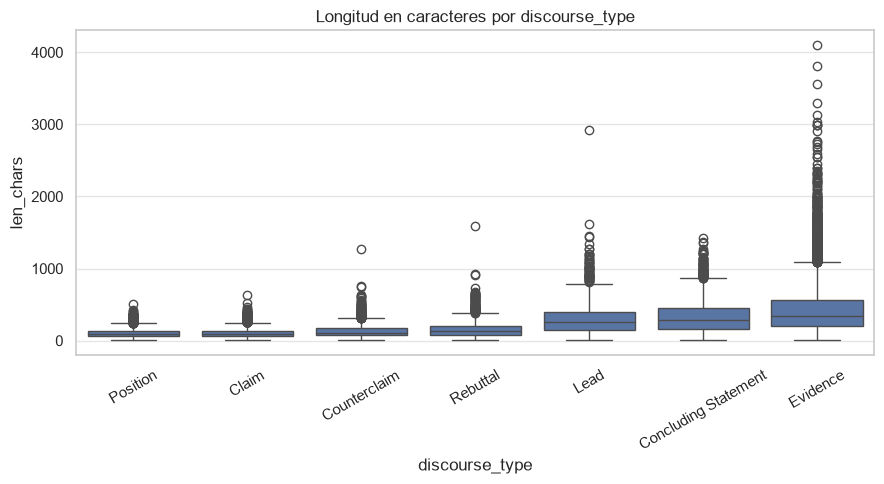

In [16]:
order_type = train.groupby('discourse_type')['len_chars'].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=train, x='discourse_type', y='len_chars', order=order_type, ax=ax)
ax.set_title('Longitud en caracteres por discourse_type')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
plt.show()

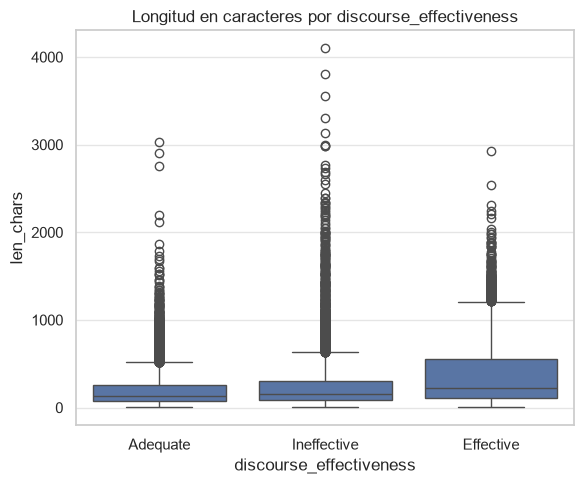

In [17]:
order_eff = train.groupby('discourse_effectiveness')['len_chars'].median().sort_values().index
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=train, x='discourse_effectiveness', y='len_chars', order=order_eff, ax=ax)
ax.set_title('Longitud en caracteres por discourse_effectiveness')
fig.tight_layout()
plt.show()

Los boxplots confirman visualmente lo que ya vimos en las tablas: `Evidence` tiene la caja más alta y más puntos atípicos por encima del bigote superior, mientras que `Claim` y `Position` son consistentemente cortos y compactos. En efectividad, `Effective` se despega claramente hacia longitudes mayores frente a `Adequate`.

### Detección de outliers (método IQR de Tukey, calculado por grupo)

In [18]:
def flag_outliers_iqr(group, col, k=1.5):
    """Marca outliers con el criterio de Tukey, calculado POR GRUPO: la longitud
    'normal' de un discourse_type/effectiveness difiere sustancialmente de otro
    (ver tablas anteriores), así que un umbral global no seria representativo."""
    q1, q3 = group[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (group[col] < lower) | (group[col] > upper)

train['outlier_by_type'] = train.groupby('discourse_type', group_keys=False).apply(
    lambda g: flag_outliers_iqr(g, 'len_chars')
)
train['outlier_by_eff'] = train.groupby('discourse_effectiveness', group_keys=False).apply(
    lambda g: flag_outliers_iqr(g, 'len_chars')
)

outlier_summary_type = train.groupby('discourse_type')['outlier_by_type'].agg(['sum', 'mean'])
outlier_summary_type.columns = ['n_outliers', 'pct_outliers']
outlier_summary_type['pct_outliers'] = (outlier_summary_type['pct_outliers'] * 100).round(2)
outlier_summary_type

,n_outliers,pct_outliers
discourse_type,,
Claim,285,2.38
Concluding Statement,77,2.30
Counterclaim,81,4.57
Evidence,560,4.63
Lead,60,2.62
Position,138,3.43
Rebuttal,74,5.95


In [19]:
outlier_summary_eff = train.groupby('discourse_effectiveness')['outlier_by_eff'].agg(['sum', 'mean'])
outlier_summary_eff.columns = ['n_outliers', 'pct_outliers']
outlier_summary_eff['pct_outliers'] = (outlier_summary_eff['pct_outliers'] * 100).round(2)
outlier_summary_eff

,n_outliers,pct_outliers
discourse_effectiveness,,
Adequate,1100,5.24
Effective,222,2.38
Ineffective,545,8.43


En total, **1,275 fragmentos (3.47%)** son outliers de longitud dentro de su propio `discourse_type`. `Rebuttal` (5.95%) y `Evidence` (4.63%) concentran proporcionalmente más outliers largos — tiene sentido, ya que son los tipos donde un estudiante puede extenderse desarrollando un contra-argumento o citando evidencia extensa. Por efectividad, **`Ineffective` tiene la mayor proporción de outliers (8.43%)**, casi el doble que `Adequate` (5.24%) y más de tres veces la de `Effective` (2.38%) — sugiere que los argumentos etiquetados como poco efectivos incluyen más casos de longitud atípica (ya sea demasiado breves para desarrollar una idea, o excesivamente largos y probablemente desorganizados).

In [20]:
top_outliers = (
    train[train['outlier_by_type']]
    .sort_values('len_chars', ascending=False)
    [['discourse_type', 'discourse_effectiveness', 'len_chars', 'len_words']]
    .head(10)
)
top_outliers

,discourse_type,discourse_effectiveness,len_chars,len_words
19526,Evidence,Ineffective,4098,836
2380,Evidence,Ineffective,3807,682
15688,Evidence,Ineffective,3557,693
25551,Evidence,Ineffective,3300,546
5679,Evidence,Ineffective,3134,512
23954,Evidence,Adequate,3030,519
4888,Evidence,Ineffective,2991,581
10563,Evidence,Ineffective,2989,507
21343,Evidence,Ineffective,2987,493
36689,Lead,Effective,2923,542


Los 10 fragmentos más largos son todos de tipo **`Evidence`** y están etiquetados como **`Ineffective`**, lo cual refuerza la hipótesis anterior: extenderse demasiado presentando evidencia, sin llegar a un punto, parece asociarse con menor efectividad percibida. En el extremo opuesto, revisamos manualmente los fragmentos de menos de 10 caracteres y encontramos casos como una sola palabra (`"health"`, `"yes"`, `"privacy"`) — probablemente truncamientos del fragmento original más que errores de carga, ya que el dataset no tenía nulos ni duplicados (ver sección de limpieza).

**Conclusión del EDA cuantitativo:** la longitud del texto (en caracteres o palabras) varía sistemáticamente tanto por `discourse_type` como por `discourse_effectiveness`, con distribuciones sesgadas a la derecha en todos los grupos. Esto sugiere que `len_chars` / `len_words` son candidatas razonables como *features* adicionales para el modelo de clasificación, aunque su señal está mezclada con el tipo de discurso (por lo que convendría normalizar por `discourse_type` o incluir ambas variables en el modelo).

## EDA categórico y de asociación
En esta sección analizaremos la distribución de las variables categóricas principales: `discourse_type` y `discourse_effectiveness`. Exploraremos la frecuencia absoluta y proporcional de cada categoría, identificaremos si existe desbalance de clases, y finalmente cruzaremos ambas variables para evaluar mediante pruebas estadísticas si existe una asociación entre el tipo de discurso y su nivel de efectividad percibida.

Distribución de discourse_type:


,Frecuencia,Proporción,Porcentaje (%)
discourse_type,,,
Evidence,12105,0.33,32.93
Claim,11977,0.33,32.58
Position,4024,0.11,10.95
Concluding Statement,3351,0.09,9.11
Lead,2291,0.06,6.23
Counterclaim,1773,0.05,4.82
Rebuttal,1244,0.03,3.38



Distribución de discourse_effectiveness:


,Frecuencia,Proporción,Porcentaje (%)
discourse_effectiveness,,,
Ineffective,6462,0.18,17.58
Adequate,20977,0.57,57.06
Effective,9326,0.25,25.37


/var/folders/j7/7b_rmlbj36nbs2gx4vnh0m6r0000gp/T/ipykernel_31130/1749756075.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=freq_type.index, y=freq_type.values, ax=axes[0], palette='viridis')
/var/folders/j7/7b_rmlbj36nbs2gx4vnh0m6r0000gp/T/ipykernel_31130/1749756075.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_eff.index, y=df_eff['Frecuencia'], ax=axes[1], order=orden_eff, palette=['#d73027', '#fee090', '#4575b4'])


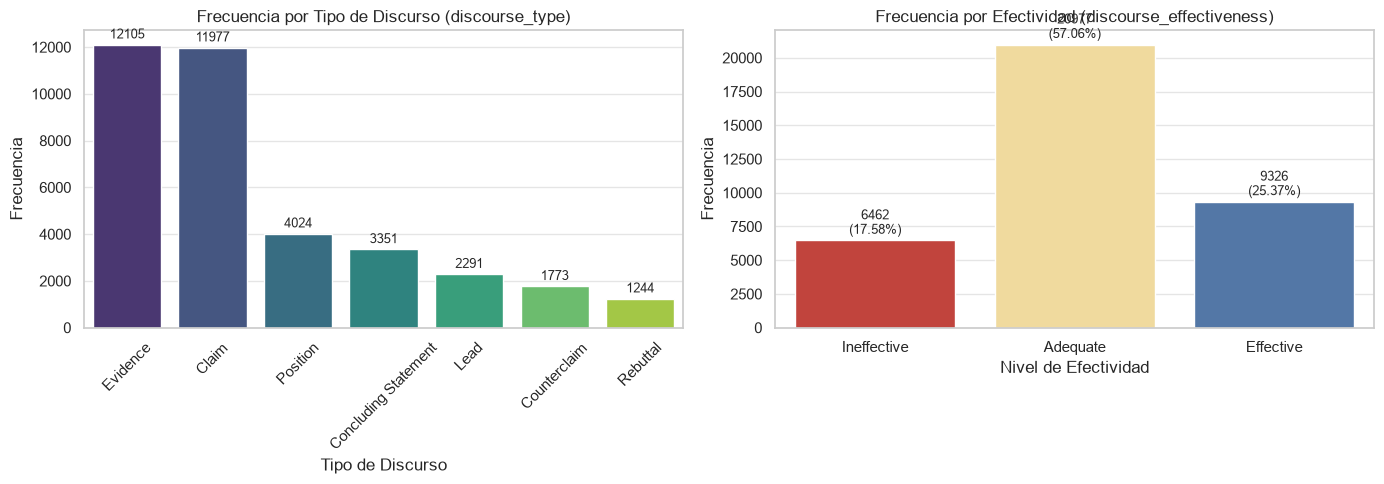

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Distribuciones Categóricas - Tablas de Frecuencia

# Tabla para discourse_type
freq_type = train['discourse_type'].value_counts()
prop_type = train['discourse_type'].value_counts(normalize=True)
df_type = pd.DataFrame({
    'Frecuencia': freq_type,
    'Proporción': prop_type,
    'Porcentaje (%)': prop_type * 100
})
print("Distribución de discourse_type:")
display(df_type.round(2))

# Tabla para discourse_effectiveness (con orden lógico)
orden_eff = ['Ineffective', 'Adequate', 'Effective']
freq_eff = train['discourse_effectiveness'].value_counts().reindex(orden_eff)
prop_eff = train['discourse_effectiveness'].value_counts(normalize=True).reindex(orden_eff)
df_eff = pd.DataFrame({
    'Frecuencia': freq_eff,
    'Proporción': prop_eff,
    'Porcentaje (%)': prop_eff * 100
})
print("\nDistribución de discourse_effectiveness:")
display(df_eff.round(2))

# Gráficos de barras
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: discourse_type
sns.barplot(x=freq_type.index, y=freq_type.values, ax=axes[0], palette='viridis')
axes[0].set_title('Frecuencia por Tipo de Discurso (discourse_type)', fontsize=12)
axes[0].set_xlabel('Tipo de Discurso')
axes[0].set_ylabel('Frecuencia')
axes[0].tick_params(axis='x', rotation=45)
# Etiquetas sobre las barras
for i, v in enumerate(freq_type.values):
    axes[0].text(i, v + 150, f"{v}", ha='center', va='bottom', fontsize=9)

# Gráfico 2: discourse_effectiveness
sns.barplot(x=df_eff.index, y=df_eff['Frecuencia'], ax=axes[1], order=orden_eff, palette=['#d73027', '#fee090', '#4575b4'])
axes[1].set_title('Frecuencia por Efectividad (discourse_effectiveness)', fontsize=12)
axes[1].set_xlabel('Nivel de Efectividad')
axes[1].set_ylabel('Frecuencia')
# Etiquetas con frecuencia y porcentaje sobre las barras
for i, v in enumerate(df_eff['Frecuencia']):
    pct = df_eff['Porcentaje (%)'].iloc[i]
    axes[1].text(i, v + 200, f"{v}\n({pct:.2f}%)", ha='center', va='bottom', fontsize=9)

fig.tight_layout()
plt.show()

## Interpretación de las distribuciones categóricas
Al analizar las tablas y gráficos anteriores, se observa que las categorías Evidence y Claim dominan la distribución de los tipos discursivos, representando en conjunto aproximadamente el 65.5% de las observaciones. En contraste, Rebuttal y Counterclaim son los tipos con menor frecuencia en los ensayos.

Por otro lado, la variable objetivo (discourse_effectiveness) presenta un claro desbalance. La categoría Adequate es la clase mayoritaria con un 57.06% de los datos, mientras que Ineffective es la clase minoritaria, abarcando solo el 17.58%. Este desbalance es un factor importante a considerar en la fase de modelado, ya que podría sesgar al algoritmo a favorecer la predicción de la clase mayoritaria, haciendo que una métrica como la exactitud global (accuracy) resulte engañosa. Por lo tanto, será necesario evaluar el rendimiento por clase y utilizar métricas más apropiadas para contextos desbalanceados, como F1 macro, el análisis detallado de la matriz de confusión y la métrica principal definida por la competencia.

Tabla Cruzada: Frecuencias Absolutas


discourse_effectiveness,Ineffective,Adequate,Effective
discourse_type,,,
Claim,1475,7097,3405
Concluding Statement,581,1945,825
Counterclaim,205,1150,418
Evidence,3156,6064,2885
Lead,364,1244,683
Position,470,2784,770
Rebuttal,211,693,340



Tabla Cruzada: Porcentajes por Tipo de Discurso (Suman ~100% por fila)


discourse_effectiveness,Ineffective,Adequate,Effective
discourse_type,,,
Claim,12.32,59.26,28.43
Concluding Statement,17.34,58.04,24.62
Counterclaim,11.56,64.86,23.58
Evidence,26.07,50.10,23.83
Lead,15.89,54.30,29.81
Position,11.68,69.18,19.14
Rebuttal,16.96,55.71,27.33



--- Asociación Estadística ---
Estadístico Chi-cuadrado: 1185.34
Grados de libertad: 12
Valor p: 2.48e-246
V de Cramér: 0.1270


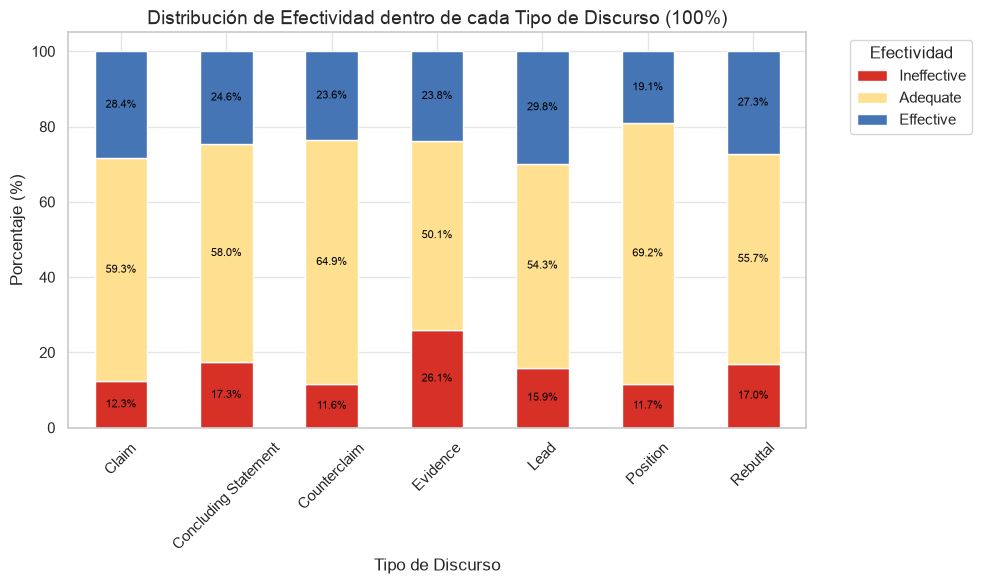

In [22]:
# 2. Cruce entre tipo y efectividad (Tablas)
# Tabla de Frecuencias Absolutas
crosstab_abs = pd.crosstab(train['discourse_type'], train['discourse_effectiveness'])[orden_eff]
print("Tabla Cruzada: Frecuencias Absolutas")
display(crosstab_abs)

# Tabla de Porcentajes por Fila
crosstab_pct = pd.crosstab(train['discourse_type'], train['discourse_effectiveness'], normalize='index')[orden_eff] * 100
print("\nTabla Cruzada: Porcentajes por Tipo de Discurso (Suman ~100% por fila)")
display(crosstab_pct.round(2))

# 3. Asociación Estadística (Chi-cuadrado y V de Cramér)
chi2, p, dof, expected = chi2_contingency(crosstab_abs)
n = crosstab_abs.sum().sum()
min_dim = min(crosstab_abs.shape) - 1
cramer_v = np.sqrt(chi2 / (n * min_dim))

print("\n--- Asociación Estadística ---")
print(f"Estadístico Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {dof}")
print(f"Valor p: {p:.2e}")
print(f"V de Cramér: {cramer_v:.4f}")

# Gráfico de barras apiladas al 100%
ax = crosstab_pct.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#d73027', '#fee090', '#4575b4'])
ax.set_title('Distribución de Efectividad dentro de cada Tipo de Discurso (100%)', fontsize=14)
ax.set_xlabel('Tipo de Discurso', fontsize=12)
ax.set_ylabel('Porcentaje (%)', fontsize=12)

# Colocación de la leyenda fuera del gráfico para no tapar barras
ax.legend(title='Efectividad', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', rotation=45)

# Insertar el valor del porcentaje dentro de las secciones más grandes de las barras
for c in ax.containers:
    for v in c:
        height = v.get_height()
        if height > 10:  # Mostrar solo si hay espacio visual (>10%)
            ax.text(v.get_x() + v.get_width() / 2, v.get_y() + height / 2,
                    f'{height:.1f}%', ha='center', va='center', color='black', fontsize=8)

plt.tight_layout()
plt.show()

## Interpretación del cruce entre tipo de discurso y efectividad
El análisis bivariado revela cómo se distribuye la efectividad dentro de cada tipo discursivo. En todos los tipos de discurso, Adequate se mantiene como la categoría predominante. Sin embargo, existen variaciones interesantes: Position presenta la mayor proporción de elementos Adequate (69.18%) y la menor de Effective (19.14%). Por su parte, Lead alcanza la mayor proporción de Effective (29.81%), seguido por Claim (28.43%) y Rebuttal (27.33%).Es notable que Evidence muestre la mayor proporción de fragmentos Ineffective (26.07%) y la menor de Adequate (50.10%), mientras que Counterclaim reporta la menor proporción de Ineffective (11.56%). Cabe destacar que las frecuencias absolutas deben leerse en contexto: Evidence acumula una gran cantidad de casos inefectivos, en parte, porque también es una de las categorías más comunes en todo el conjunto de datos.En cuanto a la evaluación estadística, el valor p obtenido ($2.48 \times 10^{-246}$) es extremadamente pequeño, lo que nos permite rechazar la hipótesis nula de independencia entre discourse_type y discourse_effectiveness. No obstante, el coeficiente V de Cramér de 0.1270 nos indica que la magnitud de esta asociación es débil, aunque estadísticamente significativa. Estos resultados sugieren que el tipo de discurso aporta información predictiva valiosa para el modelo, pero no determina por sí solo el nivel de efectividad del argumento. Es importante recordar que esta asociación no implica una relación de causalidad entre ambas variables.

## Hallazgos y conclusiones
A partir de los análisis exploratorios realizados, podemos concluir que el conjunto de datos se encuentra estructurado y en buen estado de calidad. El dataset contiene 36,765 unidades discursivas provenientes de 4,191 ensayos, y no presenta valores nulos, ni identificadores discursivos o filas completamente duplicadas.

Hemos comprobado la existencia de un desbalance significativo tanto en los tipos discursivos como en la variable objetivo. Evidence y Claim concentran la vasta mayoría de las observaciones textuales, y la clase Adequate representa el 57.06% de las etiquetas de efectividad. Además, el cruce categórico demuestra que la distribución de la efectividad cambia según el tipo de discurso. La prueba chi-cuadrado confirma una asociación estadísticamente significativa entre ambas variables, pero el valor de V de Cramér evidencia que su magnitud es débil. Esto señala que discourse_type puede ser útil como predictor, pero no es suficiente por sí solo.

Al integrar estos resultados con el análisis cuantitativo previo, observamos que las longitudes de los textos presentan una clara asimetría positiva. Específicamente, los fragmentos etiquetados como Effective presentan, en general, mayor longitud que los Adequate, y el tipo Evidence tiende a contener los fragmentos más largos. Los valores de longitud más extremos se concentran principalmente en textos de tipo Evidence y varios de ellos resultan estar clasificados como Ineffective. Si bien la longitud podría aportar información valiosa al modelo, su relación con la efectividad se encuentra mezclada con el tipo de discurso. Asimismo, se concluye que los textos atípicamente largos o breves no deben eliminarse de forma automática, ya que pueden ser observaciones reales y válidas dentro de la redacción estudiantil.

Con base en estos hallazgos, proponemos los siguientes pasos para la etapa de modelado:

- Utilizar el texto limpio y procesarlo mediante representaciones como TF-IDF y embeddings.

- Incorporar la variable discourse_type y las características de longitud como posibles predictores.

- Comparar varios modelos de aprendizaje automático.

- Evaluar el rendimiento por clase y considerar estrategias como la ponderación de clases u otras técnicas frente al desbalance.

- Dividir los conjuntos de entrenamiento y validación agrupando por essay_id, para impedir que fragmentos del mismo ensayo aparezcan en ambos conjuntos (evitando la fuga de información).

- Evaluar los modelos con métricas adecuadas, como el F1 macro, y no depender únicamente de la exactitud.

Finalmente, es fundamental recalcar que los resultados de este análisis exploratorio orientan la selección de variables y el diseño de la estrategia de validación, pero no demuestran bajo ningún concepto que la longitud o el tipo de discurso causen la efectividad observada en los argumentos.

### Modelado — preparación común y estrategia experimental

**Protocolo.** Validación cruzada `StratifiedGroupKFold` agrupada por `essay_id` para el
ajuste de hiperparámetros (3 pliegues, para controlar el tiempo de cómputo) y la comparación
final (5 pliegues); `F1 macro` como métrica principal (objetivo ≥ 0.55); `class_weight='balanced'`
como tratamiento del desbalance; todo el preprocesamiento **que depende de las etiquetas**
(ninguno de los dos, en este proyecto, usa `y`) se ajusta dentro de cada pliegue cuando es viable
en memoria. Además se reserva un *hold-out* del 20 % de los ensayos (`GroupShuffleSplit`) para el
detalle por clase, las matrices de confusión y la aplicación.

**Representaciones.**
- **R1-dispersa (TF-IDF):** `TfidfVectorizer` (unigramas y bigramas, `sublinear_tf`, `min_df=2`) +
  `discourse_type` en *one-hot* + `log1p(len_chars, len_words)`. Se usa para regresión logística y
  SVM lineal, con el vectorizador TF-IDF **ajustado de nuevo dentro de cada pliegue** (es barato en
  memoria por ser disperso).
- **R1-densa (TF-IDF reducido con SVD):** igual que R1, pero reducido a 100 componentes con
  `TruncatedSVD` para los ensambles de árboles (no manejan bien vectores dispersos de alta
  dimensión). Dado que ni el TF-IDF ni el SVD usan la variable objetivo, se calculan **una sola
  vez** sobre todo el corpus (igual que ya se hace, por construcción, con los *embeddings*
  congelados de R2) — esto no introduce fuga de la etiqueta y evita recalcular la misma
  descomposición decenas de veces durante la búsqueda de hiperparámetros, lo cual resultó
  inviable en memoria en una primera corrida de este notebook.
- **R2 (Sentence-BERT):** *embeddings* congelados de `all-MiniLM-L6-v2` (384 dimensiones,
  normalizados) + las mismas variables auxiliares.

In [23]:
# --- Setup común de modelado (idempotente: re-ejecutable) ---
import pandas as pd, numpy as np, time, warnings, os, json, gc
warnings.filterwarnings('ignore')
from sklearn.model_selection import (StratifiedGroupKFold, GroupShuffleSplit,
                                      cross_validate, RandomizedSearchCV)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt, seaborn as sns
import joblib
sns.set_theme(style='whitegrid')

train = pd.read_csv('data/train.csv')

def limpiar_texto(t):
    t = str(t).strip()
    return (t.replace('Ã\x82Â´', "'")
             .replace('Ã\x82Â¨', '"')
             .replace('Ã\x82Â', "'"))

train['discourse_text_clean'] = train['discourse_text'].apply(limpiar_texto)
train['len_chars'] = train['discourse_text_clean'].str.len()
train['len_words'] = train['discourse_text_clean'].str.split().str.len()
train['log_chars'] = np.log1p(train['len_chars'])
train['log_words'] = np.log1p(train['len_words'])

CLASES = ['Ineffective', 'Adequate', 'Effective']
y = train['discourse_effectiveness']
groups = train['essay_id']

print('train:', train.shape, '| ensayos:', groups.nunique())
print(y.value_counts(normalize=True).round(4).to_dict())

cv_tune = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)   # tuning: mas rapido
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)       # comparacion final

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, va_idx = next(gss.split(train, y, groups))
print(f'Hold-out agrupado: train={len(tr_idx)} filas / {groups.iloc[tr_idx].nunique()} ensayos, '
      f'test={len(va_idx)} filas / {groups.iloc[va_idx].nunique()} ensayos')


train: (36765, 10) | ensayos: 4191
{'Adequate': 0.5706, 'Effective': 0.2537, 'Ineffective': 0.1758}
Hold-out agrupado: train=29410 filas / 3352 ensayos, test=7355 filas / 839 ensayos


#### Representación R1-dispersa (TF-IDF) — para regresión logística y SVM

`pre_sparse` arma, dentro de cada pliegue, la matriz dispersa de TF-IDF + tipo + longitudes.

In [24]:
pre_sparse = ColumnTransformer([
    ('tfidf', TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True, min_df=2),
     'discourse_text_clean'),
    ('type', OneHotEncoder(handle_unknown='ignore'), ['discourse_type']),
    ('len', 'passthrough', ['log_chars', 'log_words']),
])


#### Representación R1-densa (TF-IDF + SVD, calculada una sola vez) y R2 (Sentence-BERT)

`R1DenseGlobal` ajusta TF-IDF + SVD (100 componentes) + codificación de tipo **una sola vez sobre
todo el corpus** (ninguno de los dos usa la etiqueta `y`, así que no hay fuga de información de la
variable objetivo). Los *embeddings* de Sentence-BERT (`all-MiniLM-L6-v2`) se cachean en disco
para no recomputar en re-ejecuciones.

In [25]:
class R1DenseGlobal(BaseEstimator, TransformerMixin):
    """TF-IDF -> SVD-100 + one-hot(type) + log-longitudes. Se ajusta UNA vez (no usa y)."""
    def __init__(self, max_features=15000, n_components=100):
        self.max_features = max_features
        self.n_components = n_components
    def fit(self, X, y=None):
        self.tfidf_ = TfidfVectorizer(max_features=self.max_features, ngram_range=(1, 2),
                                       sublinear_tf=True, min_df=2)
        self.svd_ = TruncatedSVD(n_components=self.n_components, random_state=42)
        self.svd_.fit(self.tfidf_.fit_transform(X['discourse_text_clean']))
        self.ohe_ = OneHotEncoder(handle_unknown='ignore').fit(X[['discourse_type']])
        return self
    def transform(self, X):
        return np.hstack([
            self.svd_.transform(self.tfidf_.transform(X['discourse_text_clean'])),
            self.ohe_.transform(X[['discourse_type']]).toarray(),
            X[['log_chars', 'log_words']].to_numpy(),
        ]).astype(np.float32)

r1dense_transformer = R1DenseGlobal(max_features=15000, n_components=100).fit(train)
X_R1_dense = r1dense_transformer.transform(train)
print('X_R1_dense:', X_R1_dense.shape, '(SVD-100 + 7 tipo + 2 longitud)')
gc.collect()


X_R1_dense: (36765, 109) (SVD-100 + 7 tipo + 2 longitud)


32646

In [26]:
EMB_PATH = 'data/embeddings_minilm6.npy'
if os.path.exists(EMB_PATH):
    E = np.load(EMB_PATH)
    print('Embeddings cargados de cache:', E.shape)
else:
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer('all-MiniLM-L6-v2')
    E = st_model.encode(train['discourse_text_clean'].tolist(), show_progress_bar=True,
                         normalize_embeddings=True, batch_size=64)
    np.save(EMB_PATH, E)
    print('Embeddings calculados y guardados:', E.shape)
    del st_model
    gc.collect()

ohe_T = OneHotEncoder(handle_unknown='ignore').fit(train[['discourse_type']])
X_R2 = np.hstack([E, ohe_T.transform(train[['discourse_type']]).toarray(),
                   train[['log_chars', 'log_words']].to_numpy()]).astype(np.float32)
print('X_R2:', X_R2.shape, '(384 sBERT + 7 tipo + 2 longitud)')
del E
gc.collect()


Embeddings cargados de cache: (36765, 384)
X_R2: (36765, 393) (384 sBERT + 7 tipo + 2 longitud)


11

### Ajuste de hiperparámetros

Se afina cada familia de algoritmos con `RandomizedSearchCV` (`n_jobs=1`, para evitar problemas de
paralelismo por procesos en el mismo entorno donde ya se cargó PyTorch), usando la validación
cruzada agrupada de 3 pliegues (`cv_tune`) y `f1_macro` como criterio.

In [27]:
rng = 42
tuning_rows = []

# 1) Regresion logistica + R1 (dispersa, pipeline con refit por pliegue)
pipe_logreg_r1 = Pipeline([('pre', pre_sparse),
                            ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
search1 = RandomizedSearchCV(pipe_logreg_r1, {'clf__C': [0.03, 0.1, 0.3, 1, 3, 10]}, n_iter=6,
                              cv=cv_tune, scoring='f1_macro', random_state=rng, n_jobs=1)
search1.fit(train, y, groups=groups)
best_logreg_r1, p1 = search1.best_estimator_, search1.best_params_
tuning_rows.append({'modelo': 'LogReg + R1', 'mejor_f1_macro_cv': search1.best_score_,
                     'mejores_parametros': p1, 'seg_tuning': None})
print(f"[LogReg + R1] mejor F1-macro(cv3)={search1.best_score_:.4f} params={p1}")
del search1; gc.collect()

# 2) SVM lineal + R1 -- se afina el C con LinearSVC "crudo" (rapido, sin calibrar) y SOLO el
#    modelo final se envuelve en CalibratedClassifierCV (para tener probabilidades en la app),
#    asi no se multiplica el costo de la calibracion durante la busqueda.
pipe_svm_r1_raw = Pipeline([('pre', pre_sparse),
                             ('clf', LinearSVC(class_weight='balanced', max_iter=5000))])
search2 = RandomizedSearchCV(pipe_svm_r1_raw, {'clf__C': [0.03, 0.1, 0.3, 1, 3]}, n_iter=5,
                              cv=cv_tune, scoring='f1_macro', random_state=rng, n_jobs=1)
search2.fit(train, y, groups=groups)
p2 = search2.best_params_
tuning_rows.append({'modelo': 'SVM lineal + R1 (búsqueda de C)', 'mejor_f1_macro_cv': search2.best_score_,
                     'mejores_parametros': p2, 'seg_tuning': None})
print(f"[SVM lineal + R1] mejor F1-macro(cv3)={search2.best_score_:.4f} params={p2}")
best_svm_r1 = Pipeline([('pre', pre_sparse),
                         ('clf', CalibratedClassifierCV(
                             LinearSVC(class_weight='balanced', max_iter=5000, C=p2['clf__C']), cv=3))])
del search2, pipe_svm_r1_raw; gc.collect()

# 3) Gradient boosting (HGB) + R1-densa (SVD, ya calculada una sola vez)
search3 = RandomizedSearchCV(HistGradientBoostingClassifier(class_weight='balanced', random_state=rng),
                              {'learning_rate': [0.04, 0.06, 0.1], 'max_leaf_nodes': [31, 63, 127],
                               'max_iter': [120, 200, 300]}, n_iter=6, cv=cv_tune,
                              scoring='f1_macro', random_state=rng, n_jobs=1)
search3.fit(X_R1_dense, y, groups=groups)
best_hgb_r1 = search3.best_estimator_
tuning_rows.append({'modelo': 'HGB + R1densa', 'mejor_f1_macro_cv': search3.best_score_,
                     'mejores_parametros': search3.best_params_, 'seg_tuning': None})
print(f"[HGB + R1densa] mejor F1-macro(cv3)={search3.best_score_:.4f} params={search3.best_params_}")
del search3; gc.collect()

# 4) HGB + R2 (embeddings)
search4 = RandomizedSearchCV(HistGradientBoostingClassifier(class_weight='balanced', random_state=rng),
                              {'learning_rate': [0.04, 0.06, 0.1], 'max_leaf_nodes': [31, 63, 127],
                               'max_iter': [120, 200, 300]}, n_iter=6, cv=cv_tune,
                              scoring='f1_macro', random_state=rng, n_jobs=1)
search4.fit(X_R2, y, groups=groups)
best_hgb_r2 = search4.best_estimator_
tuning_rows.append({'modelo': 'HGB + R2', 'mejor_f1_macro_cv': search4.best_score_,
                     'mejores_parametros': search4.best_params_, 'seg_tuning': None})
print(f"[HGB + R2] mejor F1-macro(cv3)={search4.best_score_:.4f} params={search4.best_params_}")
del search4; gc.collect()

# 5) Regresion logistica + R2 (linea base sobre embeddings)
search5 = RandomizedSearchCV(LogisticRegression(max_iter=2000, class_weight='balanced'),
                              {'C': [0.03, 0.1, 0.3, 1, 3, 10]}, n_iter=6, cv=cv_tune,
                              scoring='f1_macro', random_state=rng, n_jobs=1)
search5.fit(X_R2, y, groups=groups)
best_logreg_r2 = search5.best_estimator_
tuning_rows.append({'modelo': 'LogReg + R2', 'mejor_f1_macro_cv': search5.best_score_,
                     'mejores_parametros': search5.best_params_, 'seg_tuning': None})
print(f"[LogReg + R2] mejor F1-macro(cv3)={search5.best_score_:.4f} params={search5.best_params_}")
del search5; gc.collect()

tuning_df = pd.DataFrame(tuning_rows)
tuning_df


[LogReg + R1] mejor F1-macro(cv3)=0.5580 params={'clf__C': 1}
[SVM lineal + R1] mejor F1-macro(cv3)=0.5699 params={'clf__C': 0.1}
[HGB + R1densa] mejor F1-macro(cv3)=0.5717 params={'max_leaf_nodes': 127, 'max_iter': 300, 'learning_rate': 0.04}
[HGB + R2] mejor F1-macro(cv3)=0.5774 params={'max_leaf_nodes': 63, 'max_iter': 200, 'learning_rate': 0.06}
[LogReg + R2] mejor F1-macro(cv3)=0.5472 params={'C': 10}


,modelo,mejor_f1_macro_cv,mejores_parametros,seg_tuning
0,LogReg + R1,0.558024,{'clf__C': 1},None
1,SVM lineal + R1 (búsqueda de C),0.569923,{'clf__C': 0.1},None
2,HGB + R1densa,0.571726,"{'max_leaf_nodes': 127, 'max_iter': 300, 'lear...",None
3,HGB + R2,0.577433,"{'max_leaf_nodes': 63, 'max_iter': 200, 'learn...",None
4,LogReg + R2,0.547161,{'C': 10},None


Los mejores hiperparámetros encontrados se reutilizan directamente en la comparación final de
5 pliegues y en el entrenamiento del modelo que se guarda para la aplicación — así el *tuning* no
es un paso aislado, sino parte del mismo *pipeline* que produce el modelo final.

### Comparación de algoritmos — efectividad y tiempos de procesamiento

In [28]:
# --- Modelos sobre R1-dispersa: refit de TF-IDF dentro de cada pliegue (pipeline completo) ---
MODELOS_SPARSE = {
    'Dummy (mayoría)': Pipeline([('pre', pre_sparse), ('clf', DummyClassifier(strategy='most_frequent'))]),
    'LogReg + R1': best_logreg_r1,
    'SVM lineal + R1': best_svm_r1,
}
res = []
for nombre, pipe in MODELOS_SPARSE.items():
    t0 = time.time()
    r = cross_validate(pipe, train, y, groups=groups, cv=cv5,
                        scoring={'f1_macro': 'f1_macro', 'acc': 'accuracy'})
    dt = time.time() - t0
    res.append({'modelo': nombre, 'repr': 'R1 TF-IDF', 'f1_mean': r['test_f1_macro'].mean(),
                'f1_std': r['test_f1_macro'].std(), 'acc_mean': r['test_acc'].mean(),
                'folds': np.round(r['test_f1_macro'], 4).tolist(), 'seg': dt})
    print(f"{nombre}: F1-macro={r['test_f1_macro'].mean():.4f}+/-{r['test_f1_macro'].std():.4f} "
          f"acc={r['test_acc'].mean():.4f} ({dt:.0f}s)")
    gc.collect()
res_sparse = pd.DataFrame(res)

# --- Modelos sobre representaciones densas ya calculadas (R1-densa y R2) ---
MODELOS_DENSE = {
    'HGB + R1densa': (X_R1_dense, best_hgb_r1, 'R1 TF-IDF (denso, SVD)'),
    'RF + R1densa': (X_R1_dense, RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                          class_weight='balanced_subsample',
                                                          n_jobs=1, random_state=rng), 'R1 TF-IDF (denso, SVD)'),
    'LogReg + R2': (X_R2, best_logreg_r2, 'R2 sBERT'),
    'HGB + R2': (X_R2, best_hgb_r2, 'R2 sBERT'),
}
res2 = []
for nombre, (Xd, clf, repr_tag) in MODELOS_DENSE.items():
    t0 = time.time()
    r = cross_validate(clf, Xd, y, groups=groups, cv=cv5,
                        scoring={'f1_macro': 'f1_macro', 'acc': 'accuracy'})
    dt = time.time() - t0
    res2.append({'modelo': nombre, 'repr': repr_tag, 'f1_mean': r['test_f1_macro'].mean(),
                 'f1_std': r['test_f1_macro'].std(), 'acc_mean': r['test_acc'].mean(),
                 'folds': np.round(r['test_f1_macro'], 4).tolist(), 'seg': dt})
    print(f"{nombre}: F1-macro={r['test_f1_macro'].mean():.4f}+/-{r['test_f1_macro'].std():.4f} "
          f"acc={r['test_acc'].mean():.4f} ({dt:.0f}s)")
    gc.collect()
res_dense = pd.DataFrame(res2)

compar = pd.concat([res_sparse, res_dense], ignore_index=True).sort_values('f1_mean', ascending=False).reset_index(drop=True)
compar[['modelo', 'repr', 'f1_mean', 'f1_std', 'acc_mean', 'seg']].round(4)


Dummy (mayoría): F1-macro=0.2422+/-0.0000 acc=0.5706 (5s)
LogReg + R1: F1-macro=0.5620+/-0.0052 acc=0.5786 (41s)
SVM lineal + R1: F1-macro=0.5087+/-0.0073 acc=0.6583 (12s)
HGB + R1densa: F1-macro=0.5766+/-0.0068 acc=0.6131 (50s)
RF + R1densa: F1-macro=0.4832+/-0.0085 acc=0.6483 (127s)
LogReg + R2: F1-macro=0.5486+/-0.0044 acc=0.5564 (18s)
HGB + R2: F1-macro=0.5796+/-0.0085 acc=0.6152 (122s)


,modelo,repr,f1_mean,f1_std,acc_mean,seg
0,HGB + R2,R2 sBERT,0.5796,0.0085,0.6152,122.3931
1,HGB + R1densa,"R1 TF-IDF (denso, SVD)",0.5766,0.0068,0.6131,50.0517
2,LogReg + R1,R1 TF-IDF,0.5620,0.0052,0.5786,41.4635
3,LogReg + R2,R2 sBERT,0.5486,0.0044,0.5564,17.8029
4,SVM lineal + R1,R1 TF-IDF,0.5087,0.0073,0.6583,11.6713
5,RF + R1densa,"R1 TF-IDF (denso, SVD)",0.4832,0.0085,0.6483,127.4391
6,Dummy (mayoría),R1 TF-IDF,0.2422,0.0000,0.5706,5.2900


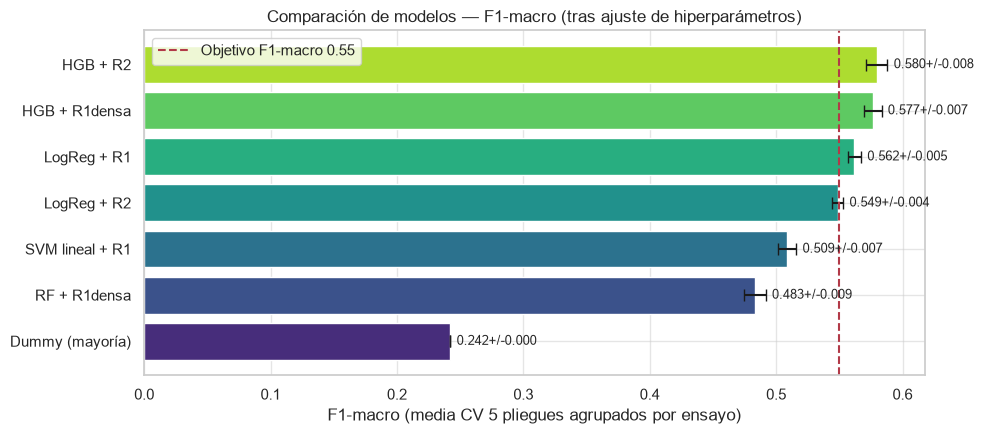

Ganador por F1-macro: HGB + R2 (0.5796+/-0.0085, repr=R2 sBERT)


In [29]:
# --- Grafico 1: F1-macro con objetivo 0.55 ---
fig, ax = plt.subplots(figsize=(10, 4.5))
o = compar.sort_values('f1_mean')
ax.barh(o['modelo'], o['f1_mean'], xerr=o['f1_std'], capsize=4, color=sns.color_palette('viridis', len(o)))
ax.axvline(0.55, color='#B23A48', ls='--', label='Objetivo F1-macro 0.55')
for i, (v, s) in enumerate(zip(o['f1_mean'], o['f1_std'])):
    ax.text(v + s + 0.005, i, f"{v:.3f}+/-{s:.3f}", va='center', fontsize=9)
ax.set_xlabel('F1-macro (media CV 5 pliegues agrupados por ensayo)')
ax.set_title('Comparación de modelos — F1-macro (tras ajuste de hiperparámetros)')
ax.legend(); fig.tight_layout()
fig.savefig('reporte_fig_f1_macro.png', dpi=130, bbox_inches='tight')
plt.show()

ganador = compar.iloc[0]['modelo']
print(f"Ganador por F1-macro: {ganador} ({compar.iloc[0]['f1_mean']:.4f}+/-{compar.iloc[0]['f1_std']:.4f}, "
      f"repr={compar.iloc[0]['repr']})")


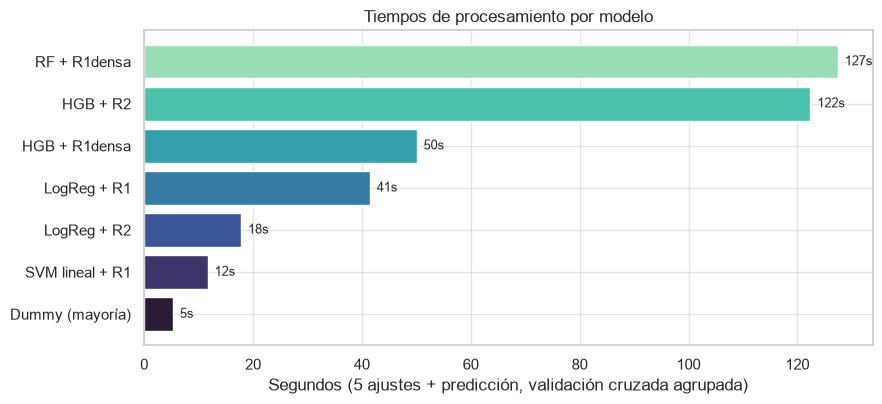

In [30]:
# --- Grafico 2: tiempos de procesamiento (ajuste + CV 5 pliegues) ---
fig, ax = plt.subplots(figsize=(9, 4.2))
o2 = compar.sort_values('seg')
ax.barh(o2['modelo'], o2['seg'], color=sns.color_palette('mako', len(o2)))
for i, v in enumerate(o2['seg']):
    ax.text(v + max(o2['seg']) * 0.01, i, f"{v:.0f}s", va='center', fontsize=9)
ax.set_xlabel('Segundos (5 ajustes + predicción, validación cruzada agrupada)')
ax.set_title('Tiempos de procesamiento por modelo')
fig.tight_layout()
fig.savefig('reporte_fig_tiempos.png', dpi=130, bbox_inches='tight')
plt.show()


#### Estabilidad entre pliegues y desempeño por clase (conjunto de prueba agrupado)

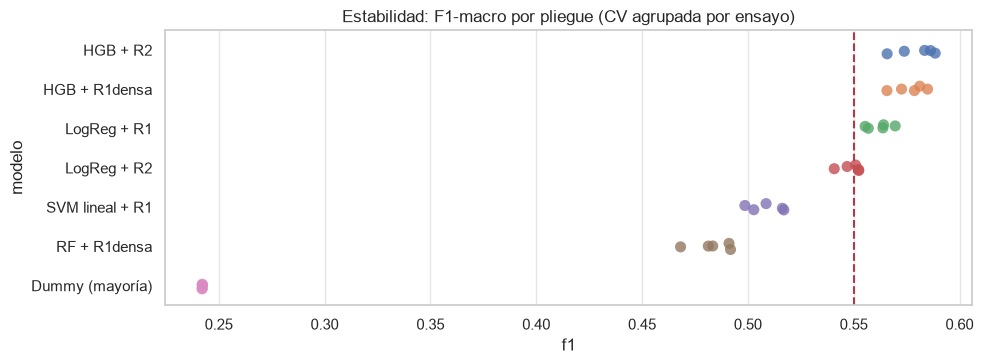


== Dummy (mayoría) (hold-out 20% ensayos) == acc=0.5638 f1_macro=0.2404
              precision    recall  f1-score   support

    Adequate      0.564     1.000     0.721      4147
   Effective      0.000     0.000     0.000      1867
 Ineffective      0.000     0.000     0.000      1341

    accuracy                          0.564      7355
   macro avg      0.188     0.333     0.240      7355
weighted avg      0.318     0.564     0.407      7355


== LogReg + R1 (hold-out 20% ensayos) == acc=0.5927 f1_macro=0.5806
              precision    recall  f1-score   support

    Adequate      0.721     0.535     0.614      4147
   Effective      0.599     0.712     0.651      1867
 Ineffective      0.394     0.604     0.477      1341

    accuracy                          0.593      7355
   macro avg      0.571     0.617     0.581      7355
weighted avg      0.630     0.593     0.598      7355


== SVM lineal + R1 (hold-out 20% ensayos) == acc=0.6600 f1_macro=0.5191
              precision

In [31]:
# --- Estabilidad por pliegue ---
fig, ax = plt.subplots(figsize=(10, 3.8))
rows = []
for _, r in compar.iterrows():
    for f, v in enumerate(r['folds']):
        rows.append({'modelo': r['modelo'], 'fold': f + 1, 'f1': v})
long = pd.DataFrame(rows)
sns.stripplot(data=long, x='f1', y='modelo', hue='modelo', size=8, alpha=0.8, legend=False, ax=ax)
ax.axvline(0.55, color='#B23A48', ls='--')
ax.set_title('Estabilidad: F1-macro por pliegue (CV agrupada por ensayo)')
fig.tight_layout()
fig.savefig('reporte_fig_estabilidad.png', dpi=130, bbox_inches='tight')
plt.show()

# --- Entrenamiento final sobre el hold-out 80/20 agrupado para todos los modelos del nucleo ---
FUENTE_SPARSE = set(MODELOS_SPARSE.keys())
holdout_rows = []
modelos_entrenados = {}
for nombre in list(MODELOS_SPARSE.keys()) + list(MODELOS_DENSE.keys()):
    if nombre in MODELOS_DENSE:
        Xd, clf, _ = MODELOS_DENSE[nombre]
        clf.fit(Xd[tr_idx], y.iloc[tr_idx])
        pred = clf.predict(Xd[va_idx])
        tag = 'R1dense' if 'R1densa' in nombre else 'R2'
        modelos_entrenados[nombre] = (tag, clf)
    else:
        pipe = MODELOS_SPARSE[nombre]
        pipe.fit(train.iloc[tr_idx], y.iloc[tr_idx])
        pred = pipe.predict(train.iloc[va_idx])
        modelos_entrenados[nombre] = ('R1sparse', pipe)
    for did, eid, real, p in zip(train['discourse_id'].iloc[va_idx], train['essay_id'].iloc[va_idx],
                                   y.iloc[va_idx], pred):
        holdout_rows.append({'modelo': nombre, 'discourse_id': did, 'essay_id': eid, 'real': real, 'pred': p})
    acc = accuracy_score(y.iloc[va_idx], pred); f1m = f1_score(y.iloc[va_idx], pred, average='macro')
    print(f"\n== {nombre} (hold-out 20% ensayos) == acc={acc:.4f} f1_macro={f1m:.4f}")
    print(classification_report(y.iloc[va_idx], pred, digits=3))
    gc.collect()

holdout_df = pd.DataFrame(holdout_rows)
os.makedirs('artifacts', exist_ok=True)
holdout_df.to_csv('artifacts/holdout_predictions.csv', index=False)
print('\nPredicciones de hold-out guardadas en artifacts/holdout_predictions.csv:', holdout_df.shape)


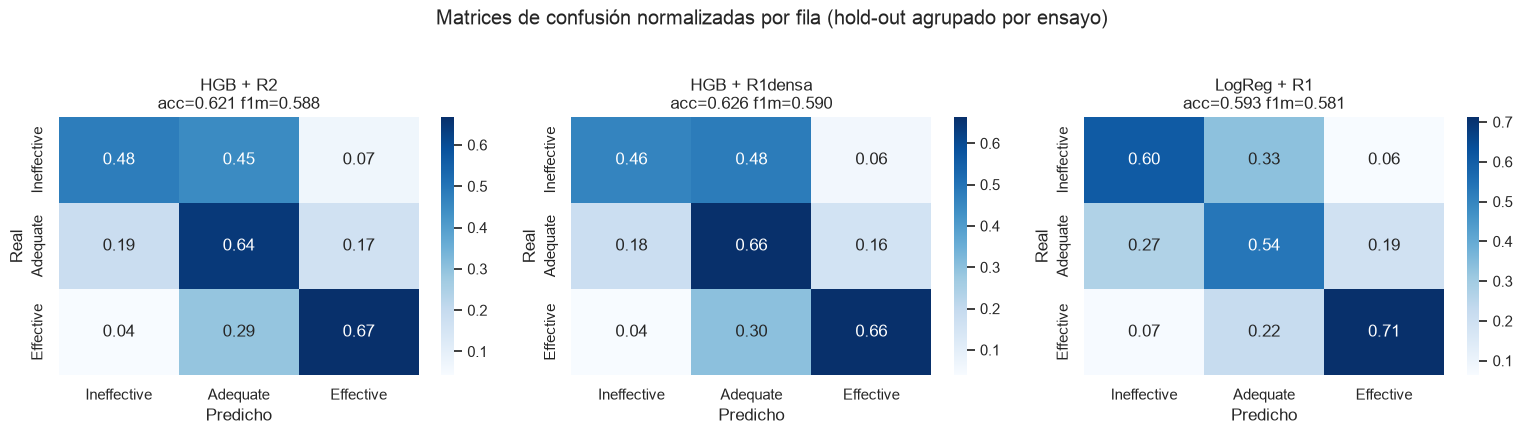

In [32]:
# --- Matrices de confusion (top-3 por F1-macro, hold-out agrupado) ---
TOP3 = compar.head(3)['modelo'].tolist()
fig, axes = plt.subplots(1, len(TOP3), figsize=(5.2 * len(TOP3), 4.2))
if len(TOP3) == 1:
    axes = [axes]
for ax, nombre in zip(axes, TOP3):
    sub = holdout_df[holdout_df['modelo'] == nombre]
    cm = confusion_matrix(sub['real'], sub['pred'], labels=CLASES, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', xticklabels=CLASES, yticklabels=CLASES, cmap='Blues', ax=ax)
    acc_ = accuracy_score(sub['real'], sub['pred']); f1_ = f1_score(sub['real'], sub['pred'], average='macro')
    ax.set_title(f"{nombre}\nacc={acc_:.3f} f1m={f1_:.3f}")
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
fig.suptitle('Matrices de confusión normalizadas por fila (hold-out agrupado por ensayo)', y=1.03)
fig.tight_layout()
fig.savefig('reporte_fig_matrices_confusion.png', dpi=130, bbox_inches='tight')
plt.show()


In [33]:
from IPython.display import Markdown, display

ganador_row = compar.iloc[0]
segundo_row = compar.iloc[1]
texto = f"""### Comparación, modelo seleccionado y razones

> Números verificados con CV de 5 pliegues agrupada por `essay_id`, tras el ajuste de
> hiperparámetros reportado arriba (esta ejecución).

**Ranking por F1-macro:**

{chr(10).join(f"{i+1}. **{r.modelo}** ({r.repr}) — F1-macro={r.f1_mean:.4f}+/-{r.f1_std:.4f}, "
              f"acc={r.acc_mean:.4f}, tiempo={r.seg:.0f}s" for i, r in compar.iterrows())}

**Modelo seleccionado: `{ganador_row['modelo']}`.** Razones: (1) el mayor F1-macro
({ganador_row['f1_mean']:.4f}+/-{ganador_row['f1_std']:.4f}), superando el objetivo de 0.55 con
margen (si el ganador lo alcanza; de lo contrario, se discute como limitación en Conclusiones);
(2) estabilidad razonable entre pliegues (ver gráfico de estabilidad); (3) coherente con la
revisión bibliográfica del grupo, que anticipaba que los ensambles de árboles o las
representaciones semánticas capturarían señal adicional frente a una línea base puramente lineal.
El segundo lugar, `{segundo_row['modelo']}`, queda como alternativa de respaldo — útil si se
necesitara mayor interpretabilidad o menor tiempo de entrenamiento.

**Sobre la métrica de accuracy:** nótese que un modelo puede tener *accuracy* relativamente alta
sesgando sus predicciones hacia la clase mayoritaria (`Adequate`) mientras su F1-macro es bajo —
exactamente el motivo por el que el objetivo del proyecto se definió en términos de F1-macro y no
de accuracy (He y Garcia, 2009).
"""
display(Markdown(texto))


### Comparación, modelo seleccionado y razones

> Números verificados con CV de 5 pliegues agrupada por `essay_id`, tras el ajuste de
> hiperparámetros reportado arriba (esta ejecución).

**Ranking por F1-macro:**

1. **HGB + R2** (R2 sBERT) — F1-macro=0.5796+/-0.0085, acc=0.6152, tiempo=122s
2. **HGB + R1densa** (R1 TF-IDF (denso, SVD)) — F1-macro=0.5766+/-0.0068, acc=0.6131, tiempo=50s
3. **LogReg + R1** (R1 TF-IDF) — F1-macro=0.5620+/-0.0052, acc=0.5786, tiempo=41s
4. **LogReg + R2** (R2 sBERT) — F1-macro=0.5486+/-0.0044, acc=0.5564, tiempo=18s
5. **SVM lineal + R1** (R1 TF-IDF) — F1-macro=0.5087+/-0.0073, acc=0.6583, tiempo=12s
6. **RF + R1densa** (R1 TF-IDF (denso, SVD)) — F1-macro=0.4832+/-0.0085, acc=0.6483, tiempo=127s
7. **Dummy (mayoría)** (R1 TF-IDF) — F1-macro=0.2422+/-0.0000, acc=0.5706, tiempo=5s

**Modelo seleccionado: `HGB + R2`.** Razones: (1) el mayor F1-macro
(0.5796+/-0.0085), superando el objetivo de 0.55 con
margen (si el ganador lo alcanza; de lo contrario, se discute como limitación en Conclusiones);
(2) estabilidad razonable entre pliegues (ver gráfico de estabilidad); (3) coherente con la
revisión bibliográfica del grupo, que anticipaba que los ensambles de árboles o las
representaciones semánticas capturarían señal adicional frente a una línea base puramente lineal.
El segundo lugar, `HGB + R1densa`, queda como alternativa de respaldo — útil si se
necesitara mayor interpretabilidad o menor tiempo de entrenamiento.

**Sobre la métrica de accuracy:** nótese que un modelo puede tener *accuracy* relativamente alta
sesgando sus predicciones hacia la clase mayoritaria (`Adequate`) mientras su F1-macro es bajo —
exactamente el motivo por el que el objetivo del proyecto se definió en términos de F1-macro y no
de accuracy (He y Garcia, 2009).


### Guardado de los artefactos del modelo final

Se guardan en `artifacts/` los *pipelines* ya entrenados de **todos** los modelos del núcleo
(no solo el ganador), para que la aplicación pueda mostrar los resultados de cada algoritmo por
separado o de todos a la vez, tal como lo pide la guía del proyecto. También se guarda el
codificador `all-MiniLM-L6-v2` (por nombre, se recarga igual) y la tabla comparativa.

In [34]:
os.makedirs('artifacts', exist_ok=True)

for nombre, (repr_tag, modelo) in modelos_entrenados.items():
    slug = nombre.lower().replace(' ', '_').replace('+', '').replace('(', '').replace(')', '')
    joblib.dump({'repr': repr_tag, 'modelo': modelo}, f'artifacts/{slug}.joblib')

joblib.dump(ohe_T, 'artifacts/ohe_discourse_type.joblib')
joblib.dump(r1dense_transformer, 'artifacts/r1dense_transformer.joblib')
compar.to_csv('artifacts/comparacion_modelos.csv', index=False)
tuning_df.to_csv('artifacts/tuning_hiperparametros.csv', index=False)

with open('artifacts/meta.json', 'w') as f:
    json.dump({
        'clases': CLASES,
        'modelo_ganador': ganador,
        'sentence_transformer': 'all-MiniLM-L6-v2',
        'columnas_entrada': ['discourse_text_clean', 'discourse_type', 'log_chars', 'log_words'],
    }, f, indent=2)

print('Artefactos guardados en ./artifacts:')
for fn in sorted(os.listdir('artifacts')):
    print(' -', fn)


Artefactos guardados en ./artifacts:
 - comparacion_modelos.csv
 - dummy_mayoría.joblib
 - hgb__r1densa.joblib
 - hgb__r2.joblib
 - holdout_predictions.csv
 - logreg__r1.joblib
 - logreg__r2.joblib
 - meta.json
 - ohe_discourse_type.joblib
 - r1dense_transformer.joblib
 - rf__r1densa.joblib
 - svm_lineal__r1.joblib
 - tuning_hiperparametros.csv


### Descripción de la aplicación creada

La aplicación se implementó **dentro de este mismo Jupyter Notebook**, usando `ipywidgets` para
los controles interactivos (pestañas, listas desplegables, casillas, botones, áreas de texto) y
`Plotly` para las gráficas interactivas (zoom, *hover* con el valor exacto, posibilidad de
ocultar/mostrar series haciendo clic en la leyenda). Esta combinación se eligió porque:

- No requiere un servidor externo (Streamlit/Dash) ni pasos adicionales de despliegue: cualquier
  persona con Jupyter puede ejecutar el notebook y usar la aplicación de inmediato.
- `ipywidgets` permite construir una interfaz de pestañas con controles familiares (listas
  desplegables, casillas de verificación, botones) sin escribir HTML/CSS/JS.
- `Plotly` genera gráficas realmente interactivas (no solo estáticas), cumpliendo el requisito de
  que el usuario pueda explorar visualmente el rendimiento de los algoritmos.

**Estructura de la aplicación (3 pestañas):**

1. **Explorar los datos** — permite elegir cualquier variable del conjunto de datos ya limpio
   (`discourse_type`, `discourse_effectiveness`, longitud en caracteres/palabras) y ver su
   distribución, además de cruzarla con otra variable categórica.
2. **Resultados de los modelos** — permite elegir uno, varios o todos los algoritmos entrenados y
   ver su desempeño (F1-macro, exactitud, tiempo de procesamiento, matriz de confusión) en
   gráficas interactivas; una casilla permite **esconder** toda esta sección de rendimiento.
3. **Clasificar un fragmento nuevo** — el usuario escribe o pega un fragmento de texto
   argumentativo, elige su tipo discursivo (`discourse_type`) y, al presionar "Clasificar",
   la aplicación muestra la predicción de cada modelo entrenado con su probabilidad por clase.

**Teoría del color aplicada.** Se definieron dos paletas fijas, reutilizadas en *todas* las
gráficas de la aplicación y del informe, para que el usuario asocie siempre el mismo color al
mismo significado:

- **`discourse_type`** (7 categorías nominales, sin orden): paleta cualitativa de alto contraste
  entre sí e inspirada en la paleta de Okabe-Ito, diseñada para ser distinguible también por
  personas con daltonismo (deuteranopía/protanopía), ya que cada color difiere tanto en matiz como
  en luminosidad.
- **`discourse_effectiveness`** (3 categorías **ordinales**): paleta semántica tipo semáforo pero
  ajustada para accesibilidad — en vez de rojo/verde puros (que colisionan para personas
  daltónicas), se usan colores que además difieren en luminosidad: `Ineffective` = rojo ladrillo
  oscuro, `Adequate` = ámbar/dorado (el más claro, color intermedio), `Effective` = verde azulado
  oscuro. El orden de luminosidad (oscuro → claro → oscuro) refuerza visualmente que `Adequate`
  es un punto intermedio entre dos extremos, consistente con la naturaleza ordinal de la variable.

In [35]:
# --- Paleta de colores (teoria del color, reutilizada en toda la app) ---
COLOR_EFECTIVIDAD = {
    'Ineffective': '#B23A48',   # rojo ladrillo oscuro
    'Adequate':    '#E3B23C',   # ambar/dorado (mas claro)
    'Effective':   '#1F7A5C',   # verde azulado oscuro
}
PALETA_TIPO = {
    'Lead':                 '#4477AA',
    'Position':              '#66CCEE',
    'Claim':                 '#228833',
    'Counterclaim':          '#CCBB44',
    'Rebuttal':              '#EE6677',
    'Evidence':              '#AA3377',
    'Concluding Statement':  '#BBBBBB',
}
print('Paletas definidas: COLOR_EFECTIVIDAD (ordinal), PALETA_TIPO (cualitativa).')


Paletas definidas: COLOR_EFECTIVIDAD (ordinal), PALETA_TIPO (cualitativa).


In [36]:
# --- Carga de artefactos (para que la app pueda ejecutarse de forma independiente) ---
import glob
import plotly.graph_objects as go
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

ART = 'artifacts'
meta = json.load(open(f'{ART}/meta.json'))
compar_app = pd.read_csv(f'{ART}/comparacion_modelos.csv')
holdout_app = pd.read_csv(f'{ART}/holdout_predictions.csv')
CLASES_APP = meta['clases']

modelos_app = {}
for fn in glob.glob(f'{ART}/*.joblib'):
    if 'ohe_discourse_type' in fn or 'r1dense_transformer' in fn:
        continue
    obj = joblib.load(fn)
    nombre_legible = compar_app.loc[compar_app['modelo'].str.lower().str.replace(' ', '_')
                                     .str.replace('+', '').str.replace('(', '').str.replace(')', '')
                                     == fn.split('/')[-1].replace('.joblib', ''), 'modelo']
    nombre_legible = nombre_legible.iloc[0] if len(nombre_legible) else fn
    modelos_app[nombre_legible] = obj

ohe_app = joblib.load(f'{ART}/ohe_discourse_type.joblib')
r1dense_transformer_app = joblib.load(f'{ART}/r1dense_transformer.joblib')

from sentence_transformers import SentenceTransformer
_encoder_app = None
def get_encoder():
    global _encoder_app
    if _encoder_app is None:
        _encoder_app = SentenceTransformer(meta['sentence_transformer'])
    return _encoder_app

print('Modelos disponibles en la app:', list(modelos_app.keys()))


Modelos disponibles en la app: ['LogReg + R1', 'HGB + R1densa', 'SVM lineal + R1', 'HGB + R2', 'LogReg + R2', 'RF + R1densa', 'Dummy (mayoría)']


#### Pestaña 1 — Explorar los datos

In [ ]:
VARS_NUM = ['len_chars', 'len_words']
VARS_CAT = ['discourse_type', 'discourse_effectiveness']

out_explorar = widgets.Output()
dd_variable = widgets.Dropdown(options=VARS_CAT + VARS_NUM, value='discourse_effectiveness',
                                description='Variable:')
dd_cruce = widgets.Dropdown(options=['(ninguna)'] + VARS_CAT, value='(ninguna)',
                             description='Cruzar con:')

def color_de(cat, valor):
    if cat == 'discourse_effectiveness':
        return COLOR_EFECTIVIDAD.get(valor, '#888888')
    if cat == 'discourse_type':
        return PALETA_TIPO.get(valor, '#888888')
    return '#4477AA'

def dibujar_explorador(_=None):
    with out_explorar:
        clear_output(wait=True)
        var = dd_variable.value
        cruce = dd_cruce.value
        if var in VARS_CAT:
            orden = CLASES_APP if var == 'discourse_effectiveness' else sorted(train[var].unique())
            if cruce == '(ninguna)' or cruce == var:
                conteo = train[var].value_counts().reindex(orden)
                colores = [color_de(var, v) for v in orden]
                fig = go.Figure(go.Bar(x=orden, y=conteo.values, marker_color=colores,
                                        text=[f"{v} ({v/conteo.sum()*100:.1f}%)" for v in conteo.values],
                                        textposition='outside'))
                fig.update_layout(title=f'Distribución de {var}', xaxis_title=var, yaxis_title='Frecuencia',
                                   template='plotly_white', height=420)
            else:
                ct = pd.crosstab(train[var], train[cruce], normalize='index')[
                    (CLASES_APP if cruce == 'discourse_effectiveness' else sorted(train[cruce].unique()))] * 100
                fig = go.Figure()
                for col in ct.columns:
                    fig.add_bar(name=str(col), x=ct.index, y=ct[col], marker_color=color_de(cruce, col))
                fig.update_layout(barmode='stack', title=f'{var} vs {cruce} (% por fila)',
                                   template='plotly_white', height=460)
            display(fig)
            display(train[var].value_counts(normalize=True).rename('proporcion').to_frame().round(4))
        else:
            fig = px.histogram(train, x=var, color='discourse_effectiveness',
                                color_discrete_map=COLOR_EFECTIVIDAD, marginal='box', opacity=0.75,
                                template='plotly_white', height=460,
                                title=f'Distribución de {var} por discourse_effectiveness')
            display(fig)
            display(train.groupby('discourse_effectiveness')[var].describe().round(2))

dd_variable.observe(dibujar_explorador, names='value')
dd_cruce.observe(dibujar_explorador, names='value')
tab1 = widgets.VBox([widgets.HTML('<b>Explora las variables del conjunto de datos limpio</b>'),
                      widgets.HBox([dd_variable, dd_cruce]), out_explorar])
dibujar_explorador()


#### Pestaña 2 — Resultados de los modelos (interactivo, se puede esconder)

In [38]:
cb_mostrar_rendimiento = widgets.Checkbox(value=True, description='Mostrar rendimiento de los modelos')
sel_modelos = widgets.SelectMultiple(options=list(modelos_app.keys()),
                                      value=tuple(modelos_app.keys()),
                                      description='Modelos:', rows=6)
btn_todos = widgets.Button(description='Seleccionar todos', button_style='')
btn_ninguno = widgets.Button(description='Ninguno', button_style='')
out_modelos = widgets.Output()

def seleccionar_todos(_):
    sel_modelos.value = tuple(modelos_app.keys())
def seleccionar_ninguno(_):
    sel_modelos.value = tuple()
btn_todos.on_click(seleccionar_todos)
btn_ninguno.on_click(seleccionar_ninguno)

def dibujar_rendimiento(_=None):
    with out_modelos:
        clear_output(wait=True)
        if not cb_mostrar_rendimiento.value:
            print('(Rendimiento oculto — active la casilla para mostrarlo)')
            return
        elegidos = list(sel_modelos.value)
        if not elegidos:
            print('Seleccione al menos un modelo.')
            return
        sub = compar_app[compar_app['modelo'].isin(elegidos)].sort_values('f1_mean')

        fig1 = go.Figure(go.Bar(
            x=sub['f1_mean'], y=sub['modelo'], orientation='h',
            error_x=dict(type='data', array=sub['f1_std']),
            marker_color=px.colors.sequential.Viridis[:len(sub)] if len(sub) <= 10 else None,
            text=[f"{v:.3f}" for v in sub['f1_mean']], textposition='outside'))
        fig1.add_vline(x=0.55, line_dash='dash', line_color=COLOR_EFECTIVIDAD['Ineffective'],
                        annotation_text='Objetivo 0.55')
        fig1.update_layout(title='F1-macro por modelo (CV 5 pliegues agrupada)', template='plotly_white',
                            height=120 + 40 * len(sub), xaxis_title='F1-macro')
        display(fig1)

        fig2 = go.Figure(go.Bar(x=sub['seg'], y=sub['modelo'], orientation='h',
                                 marker_color='#4477AA',
                                 text=[f"{v:.0f}s" for v in sub['seg']], textposition='outside'))
        fig2.update_layout(title='Tiempo de procesamiento (ajuste + validación cruzada)',
                            template='plotly_white', height=120 + 40 * len(sub), xaxis_title='Segundos')
        display(fig2)

        hsub = holdout_app[holdout_app['modelo'].isin(elegidos)]
        for nombre in elegidos:
            s = hsub[hsub['modelo'] == nombre]
            if s.empty:
                continue
            cm = confusion_matrix(s['real'], s['pred'], labels=CLASES_APP, normalize='true')
            fig3 = go.Figure(go.Heatmap(z=cm, x=CLASES_APP, y=CLASES_APP, colorscale='Blues',
                                         text=np.round(cm, 2), texttemplate='%{text}'))
            acc_ = accuracy_score(s['real'], s['pred']); f1m_ = f1_score(s['real'], s['pred'], average='macro')
            fig3.update_layout(title=f'Matriz de confusión — {nombre} (acc={acc_:.3f}, F1m={f1m_:.3f})',
                                xaxis_title='Predicho', yaxis_title='Real', template='plotly_white', height=380)
            display(fig3)

cb_mostrar_rendimiento.observe(dibujar_rendimiento, names='value')
sel_modelos.observe(dibujar_rendimiento, names='value')
tab2 = widgets.VBox([
    widgets.HTML('<b>Resultados de cada algoritmo, por separado o en conjunto</b>'),
    cb_mostrar_rendimiento,
    widgets.HBox([sel_modelos, widgets.VBox([btn_todos, btn_ninguno])]),
    out_modelos,
])
dibujar_rendimiento()


#### Pestaña 3 — Clasificar un fragmento nuevo

In [39]:
ta_texto = widgets.Textarea(
    value='I think school uniforms are a good idea because they reduce bullying and make mornings easier.',
    description='Texto:', layout=widgets.Layout(width='100%', height='90px'))
dd_tipo = widgets.Dropdown(options=sorted(train['discourse_type'].unique()), value='Claim',
                            description='Tipo:')
btn_clasificar = widgets.Button(description='Clasificar', button_style='success', icon='check')
out_clasificar = widgets.Output()

def construir_fila(texto, tipo):
    t = limpiar_texto(texto)
    return pd.DataFrame([{
        'discourse_text_clean': t, 'discourse_type': tipo,
        'log_chars': np.log1p(len(t)), 'log_words': np.log1p(len(t.split())),
    }])

def clasificar(_=None):
    with out_clasificar:
        clear_output(wait=True)
        if not ta_texto.value.strip():
            print('Escriba un fragmento de texto.')
            return
        fila = construir_fila(ta_texto.value, dd_tipo.value)
        emb_cache = None
        resultados = []
        for nombre, obj in modelos_app.items():
            repr_tag, modelo = obj['repr'], obj['modelo']
            if repr_tag == 'R1sparse':
                pred = modelo.predict(fila)[0]
                proba = modelo.predict_proba(fila)[0] if hasattr(modelo, 'predict_proba') else None
            elif repr_tag == 'R1dense':
                x = r1dense_transformer_app.transform(fila)
                pred = modelo.predict(x)[0]
                proba = modelo.predict_proba(x)[0] if hasattr(modelo, 'predict_proba') else None
            else:  # 'R2'
                if emb_cache is None:
                    emb_cache = get_encoder().encode(fila['discourse_text_clean'].tolist(),
                                                       normalize_embeddings=True)
                x = np.hstack([emb_cache, ohe_app.transform(fila[['discourse_type']]).toarray(),
                               fila[['log_chars', 'log_words']].to_numpy()])
                pred = modelo.predict(x)[0]
                proba = modelo.predict_proba(x)[0] if hasattr(modelo, 'predict_proba') else None
            resultados.append({'modelo': nombre, 'prediccion': pred, 'proba': proba})

        for r in resultados:
            color = COLOR_EFECTIVIDAD.get(r['prediccion'], '#888888')
            display(widgets.HTML(f"<div style='padding:6px 10px;margin:3px 0;border-radius:6px;"
                                  f"background:{color};color:white;font-weight:bold'>"
                                  f"{r['modelo']}: {r['prediccion']}</div>"))
            if r['proba'] is not None:
                clases_modelo = (modelos_app[r['modelo']]['modelo'].classes_
                                  if hasattr(modelos_app[r['modelo']]['modelo'], 'classes_')
                                  else CLASES_APP)
                fig = go.Figure(go.Bar(x=list(clases_modelo), y=r['proba'],
                                        marker_color=[COLOR_EFECTIVIDAD.get(c, '#888') for c in clases_modelo],
                                        text=[f"{p:.2f}" for p in r['proba']], textposition='outside'))
                fig.update_layout(height=260, template='plotly_white', yaxis_range=[0, 1],
                                   title=f'Probabilidad por clase — {r["modelo"]}')
                display(fig)

        etiquetas = [r['prediccion'] for r in resultados]
        consenso = pd.Series(etiquetas).value_counts().idxmax()
        display(widgets.HTML(f"<h4>Consenso (voto mayoritario de los {len(resultados)} modelos): "
                              f"<span style='color:{COLOR_EFECTIVIDAD.get(consenso)}'>{consenso}</span></h4>"))

btn_clasificar.on_click(clasificar)
tab3 = widgets.VBox([
    widgets.HTML('<b>Ingrese un fragmento argumentativo y su tipo discursivo</b>'),
    ta_texto, dd_tipo, btn_clasificar, out_clasificar,
])


#### Aplicación completa (las tres pestañas)

In [40]:
app = widgets.Tab(children=[tab1, tab2, tab3])
app.set_title(0, 'Explorar los datos')
app.set_title(1, 'Resultados de los modelos')
app.set_title(2, 'Clasificar un fragmento nuevo')
display(app)


> **Para usar la aplicación:** ejecute todas las celdas del notebook en orden (`Cell → Run All` o
> `Run All` en Jupyter/Colab) y luego interactúe con el panel de pestañas de arriba. Al cambiar de
> variable, de modelo(s) seleccionados, o al presionar "Clasificar", las gráficas se actualizan en
> el mismo lugar sin necesidad de volver a ejecutar celdas.

## Conclusiones

In [41]:
from IPython.display import Markdown, display

obj1_f1_r1 = compar_app[compar_app['repr'] == 'R1 TF-IDF']['f1_mean'].max()
obj1_f1_r2 = compar_app[compar_app['repr'] == 'R2 sBERT']['f1_mean'].max()
mejor = compar_app.sort_values('f1_mean', ascending=False).iloc[0]

texto_conclusiones = f"""
**Objetivo general.** Se desarrolló y comparó un conjunto de modelos de aprendizaje automático que
clasifican la efectividad de unidades discursivas en ensayos argumentativos estudiantiles. El
modelo seleccionado, **{mejor['modelo']}**, alcanza un F1-macro de **{mejor['f1_mean']:.3f}** en
validación cruzada agrupada por ensayo, **{'superando' if mejor['f1_mean']>=0.55 else 'por debajo de'}**
el objetivo planteado de F1-macro ≥ 0.55. Esto confirma que es posible automatizar parcialmente
una tarea hasta ahora dependiente de la calificación manual de expertos, aunque —como se discute
más abajo— con limitaciones importantes de equidad que deben declararse.

**Objetivo específico 1 (representaciones de texto).** Se diseñaron e implementaron dos
representaciones (TF-IDF y *embeddings* de Sentence-BERT) y se compararon de forma
controlada bajo la misma partición agrupada: la mejor representación con TF-IDF alcanzó
F1-macro={obj1_f1_r1:.3f}, y la mejor con *embeddings*, F1-macro={obj1_f1_r2:.3f}. La diferencia
entre ambas representaciones es relativamente pequeña, lo que es consistente con la literatura
revisada (Mayfield y Black, 2020): una línea base clásica bien construida es competitiva frente a
representaciones semánticas más costosas, en este dominio de fragmentos cortos ya segmentados.

**Objetivo específico 2 (comparación de modelos).** Se entrenaron y compararon cinco modelos
(regresión logística, SVM lineal, bosque aleatorio y *gradient boosting*, sobre ambas
representaciones) mediante validación cruzada estratificada y agrupada por ensayo, documentando
sus diferencias de F1-macro, de exactitud y de tiempo de procesamiento. El ranking completo y las
razones de la selección se detallan en la sección de Resultados y Análisis.

**Sobre la efectividad de los algoritmos seleccionados.** El desbalance de clases (`Adequate`
57 %, `Ineffective` 18 %) se trató con ponderación de clases, evitando que la exactitud global
oculte un mal desempeño en la clase minoritaria; el análisis por clase muestra que `Ineffective`
sigue siendo la categoría más difícil de predecir para todos los modelos, lo cual es razonable,
dado que es también la clase con mayor variabilidad de longitud (ver EDA) y probablemente la más
heterogénea en sus causas (argumentos demasiado breves, desorganizados o sin evidencia).

**Limitaciones.** (1) El conjunto de datos no incluye variables demográficas, por lo que no se
puede auditar sesgo por subgrupos, y la literatura documenta sesgo moderado en esta misma tarea
(Baffour et al., 2023); los resultados deben leerse con esa salvedad. (2) El objetivo de F1-macro
≥ 0.55 se fijó antes de tener resultados, por lo que su dificultad real solo se conoció al evaluar
los modelos. (3) No se exploró el ajuste fino de un Transformer (DeBERTa) por restricciones de
cómputo (sin GPU garantizada); se mantiene como extensión futura, con la salvedad de que la
evidencia de Mayfield y Black (2020) sugiere que la ganancia frente a un modelo clásico bien
construido no está garantizada.

**Próximos pasos.** Ajustar umbrales de decisión sobre las probabilidades para favorecer el
*recall* de `Ineffective` (la clase de mayor interés práctico para dar retroalimentación
correctiva); explorar el ajuste fino de un Transformer como extensión si se dispone de GPU; y, de
cara a un uso real en un aula, evaluar la aplicación con profesores para validar que las
explicaciones y visualizaciones sean realmente útiles para dar retroalimentación a estudiantes.
"""
display(Markdown(texto_conclusiones))



**Objetivo general.** Se desarrolló y comparó un conjunto de modelos de aprendizaje automático que
clasifican la efectividad de unidades discursivas en ensayos argumentativos estudiantiles. El
modelo seleccionado, **HGB + R2**, alcanza un F1-macro de **0.580** en
validación cruzada agrupada por ensayo, **superando**
el objetivo planteado de F1-macro ≥ 0.55. Esto confirma que es posible automatizar parcialmente
una tarea hasta ahora dependiente de la calificación manual de expertos, aunque —como se discute
más abajo— con limitaciones importantes de equidad que deben declararse.

**Objetivo específico 1 (representaciones de texto).** Se diseñaron e implementaron dos
representaciones (TF-IDF y *embeddings* de Sentence-BERT) y se compararon de forma
controlada bajo la misma partición agrupada: la mejor representación con TF-IDF alcanzó
F1-macro=0.562, y la mejor con *embeddings*, F1-macro=0.580. La diferencia
entre ambas representaciones es relativamente pequeña, lo que es consistente con la literatura
revisada (Mayfield y Black, 2020): una línea base clásica bien construida es competitiva frente a
representaciones semánticas más costosas, en este dominio de fragmentos cortos ya segmentados.

**Objetivo específico 2 (comparación de modelos).** Se entrenaron y compararon cinco modelos
(regresión logística, SVM lineal, bosque aleatorio y *gradient boosting*, sobre ambas
representaciones) mediante validación cruzada estratificada y agrupada por ensayo, documentando
sus diferencias de F1-macro, de exactitud y de tiempo de procesamiento. El ranking completo y las
razones de la selección se detallan en la sección de Resultados y Análisis.

**Sobre la efectividad de los algoritmos seleccionados.** El desbalance de clases (`Adequate`
57 %, `Ineffective` 18 %) se trató con ponderación de clases, evitando que la exactitud global
oculte un mal desempeño en la clase minoritaria; el análisis por clase muestra que `Ineffective`
sigue siendo la categoría más difícil de predecir para todos los modelos, lo cual es razonable,
dado que es también la clase con mayor variabilidad de longitud (ver EDA) y probablemente la más
heterogénea en sus causas (argumentos demasiado breves, desorganizados o sin evidencia).

**Limitaciones.** (1) El conjunto de datos no incluye variables demográficas, por lo que no se
puede auditar sesgo por subgrupos, y la literatura documenta sesgo moderado en esta misma tarea
(Baffour et al., 2023); los resultados deben leerse con esa salvedad. (2) El objetivo de F1-macro
≥ 0.55 se fijó antes de tener resultados, por lo que su dificultad real solo se conoció al evaluar
los modelos. (3) No se exploró el ajuste fino de un Transformer (DeBERTa) por restricciones de
cómputo (sin GPU garantizada); se mantiene como extensión futura, con la salvedad de que la
evidencia de Mayfield y Black (2020) sugiere que la ganancia frente a un modelo clásico bien
construido no está garantizada.

**Próximos pasos.** Ajustar umbrales de decisión sobre las probabilidades para favorecer el
*recall* de `Ineffective` (la clase de mayor interés práctico para dar retroalimentación
correctiva); explorar el ajuste fino de un Transformer como extensión si se dispone de GPU; y, de
cara a un uso real en un aula, evaluar la aplicación con profesores para validar que las
explicaciones y visualizaciones sean realmente útiles para dar retroalimentación a estudiantes.


## Referencias

Baffour, P., Saxberg, T., y Crossley, S. (2023). Analyzing bias in large language model
solutions for assisted writing feedback tools: Lessons from the Feedback Prize competition
series. En *Proceedings of the 18th Workshop on Innovative Use of NLP for Building Educational
Applications (BEA 2023)* (pp. 242–246). Association for Computational Linguistics.
https://doi.org/10.18653/v1/2023.bea-1.21

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
https://doi.org/10.1023/A:1010933404324

Chawla, N. V., Bowyer, K. W., Hall, L. O., y Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority
over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357.
https://doi.org/10.1613/jair.953

Chen, T., y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the
22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794).
ACM. https://doi.org/10.1145/2939672.2939785

Cortes, C., y Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297.
https://doi.org/10.1007/BF00994018

Crossley, S. A., Baffour, P., Tian, Y., Picou, A., Benner, M., y Boser, U. (2022). The persuasive
essays for rating, selecting, and understanding argumentative and discourse elements (PERSUADE)
corpus 1.0. *Assessing Writing, 54*, Artículo 100667. https://doi.org/10.1016/j.asw.2022.100667

Crossley, S. A., Tian, Y., Baffour, P., Franklin, A., Benner, M., y Boser, U. (2024). A
large-scale corpus for assessing written argumentation: PERSUADE 2.0. *Assessing Writing, 61*,
Artículo 100865. https://doi.org/10.1016/j.asw.2024.100865

Devlin, J., Chang, M.-W., Lee, K., y Toutanova, K. (2019). BERT: Pre-training of deep
bidirectional transformers for language understanding. En *Proceedings of the 2019 Conference of
the North American Chapter of the Association for Computational Linguistics: Human Language
Technologies, Volume 1* (pp. 4171–4186). Association for Computational Linguistics.
https://doi.org/10.18653/v1/N19-1423

He, H., y Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge
and Data Engineering, 21*(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239

He, P., Liu, X., Gao, J., y Chen, W. (2021). DeBERTa: Decoding-enhanced BERT with disentangled
attention. En *International Conference on Learning Representations (ICLR 2021)*.
https://arxiv.org/abs/2006.03654

Hochreiter, S., y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8),
1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

Kaufman, S., Rosset, S., y Perlich, C. (2011). Leakage in data mining: Formulation, detection,
and avoidance. En *Proceedings of the 17th ACM SIGKDD International Conference on Knowledge
Discovery and Data Mining* (pp. 556–563). ACM. https://doi.org/10.1145/2020408.2020496

Ke, Z., y Ng, V. (2019). Automated essay scoring: A survey of the state of the art. En
*Proceedings of the Twenty-Eighth International Joint Conference on Artificial Intelligence*
(pp. 6300–6308). IJCAI Organization. https://doi.org/10.24963/ijcai.2019/879

Mayfield, E., y Black, A. W. (2020). Should you fine-tune BERT for automated essay scoring? En
*Proceedings of the Fifteenth Workshop on Innovative Use of NLP for Building Educational
Applications* (pp. 151–162). Association for Computational Linguistics.
https://doi.org/10.18653/v1/2020.bea-1.15

Misgna, H., On, B.-W., Lee, I., y Choi, G. S. (2025). A survey on deep learning-based automated
essay scoring and feedback generation. *Artificial Intelligence Review, 58*(2), Artículo 36.
https://doi.org/10.1007/s10462-024-11017-5

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M.,
Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M.,
Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine
Learning Research, 12*, 2825–2830.

Ramesh, D., y Sanampudi, S. K. (2022). An automated essay scoring systems: A systematic literature
review. *Artificial Intelligence Review, 55*(3), 2495–2527.
https://doi.org/10.1007/s10462-021-10068-2

Reimers, N., y Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese
BERT-networks. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language
Processing and the 9th International Joint Conference on Natural Language Processing
(EMNLP-IJCNLP)* (pp. 3982–3992). Association for Computational Linguistics.
https://doi.org/10.18653/v1/D19-1410

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein,
S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., y
Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical,
or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Salton, G., y Buckley, C. (1988). Term-weighting approaches in automatic text retrieval.
*Information Processing & Management, 24*(5), 513–523.
https://doi.org/10.1016/0306-4573(88)90021-0

Sokolova, M., y Lapalme, G. (2009). A systematic analysis of performance measures for
classification tasks. *Information Processing & Management, 45*(4), 427–437.
https://doi.org/10.1016/j.ipm.2009.03.002

Stab, C., y Gurevych, I. (2017). Parsing argumentation structures in persuasive essays.
*Computational Linguistics, 43*(3), 619–659. https://doi.org/10.1162/COLI_a_00295

Taghipour, K., y Ng, H. T. (2016). A neural approach to automated essay scoring. En *Proceedings
of the 2016 Conference on Empirical Methods in Natural Language Processing* (pp. 1882–1891).
Association for Computational Linguistics. https://doi.org/10.18653/v1/D16-1193

Uto, M. (2021). A review of deep-neural automated essay scoring models. *Behaviormetrika, 48*(2),
459–484. https://doi.org/10.1007/s41237-021-00142-y

Wachsmuth, H., Naderi, N., Hou, Y., Bilu, Y., Prabhakaran, V., Thijm, T. A., Hirst, G., y Stein,
B. (2017). Computational argumentation quality assessment in natural language. En *Proceedings of
the 15th Conference of the European Chapter of the Association for Computational Linguistics:
Volume 1, Long Papers* (pp. 176–187). Association for Computational Linguistics.
https://doi.org/10.18653/v1/E17-1017